# GeoNUSAF — TC-SegFormer (proposed model)

**Kathmandu Valley land-use segmentation — 6 classes, `ignore_index=255`, 512x512 @ 0.586 m/px.**

This is the *proposed* model in the seven-model benchmark. It is a SegFormer with three additions,
each independently switchable so every one of them has a clean ablation:

| Component | What it is | CFG toggle | Why |
|---|---|---|---|
| **B — Thin-structure detail path** | shallow stride-2 conv branch on the raw image, fused with the decoder at H/2 | `USE_DETAIL` | SegFormer emits logits at H/4. At 0.586 m/px a 10 m road is ~17 px in the image but ~4 px at H/4 — at the aliasing limit. |
| **C — Loss + sampler** | capped effective-number CE + Lovasz (warm-ramped) + soft-clDice on Road/River, plus a class-presence-balanced sampler | `CLDICE_ENABLE`, `BALANCED_SAMPLER` | Lovasz in `present` mode only accumulates gradient for classes in the batch; River is in a small minority of tiles, so its gradient is sparse and spiky. |
| **D — Coarse-supervision-aware (CSA) reweighting** | per-pixel reliability weight from a **width-normalised** distance transform of the polygon boundaries; applied as CE weights and as a hard mask into Lovasz | `CSA_ENABLE` | The polygons were drawn coarsely. Boundary bands inject label noise into every gradient step. |

**What is deliberately NOT here: terrain / DEM conditioning.** It needs per-tile geometry to sample a
DEM window, and the QGIS Atlas coverage layer is gone, so tile centroids cannot be recovered. A
sequence-index stand-in would function as a tile ID and inflate validation. If geometry is ever
recovered, that module gets its own notebook and its own three control ablations
(shuffled-terrain / coordinates-only / per-tile-mean-broadcast).

**Width normalisation is the non-obvious part of D.** A 10 m road is 17 px wide, so *every* road
pixel is within ~8.5 px of a polygon boundary. Any fixed-pixel band would drive the whole Road and
River classes to `w_min` — down-weighting exactly the classes we are trying to rescue. The weight is
therefore a fraction of *local object width*, not an absolute distance.

Everything else — splits, grouping, weighting scheme, augmentation, optimizer, metrics, persistence —
is identical to the other six baselines.

## 1. Environment

Kaggle already has torch, cv2, scipy, skimage, sklearn. We need `transformers` (SegFormer),
`huggingface_hub`, `wandb`, and optionally `fvcore` for the GFLOPs column.

**Internet must be enabled** in notebook settings (pretrained weights, HF push, W&B).
Secrets required: `HF_TOKEN` (write scope), `WANDB_API_KEY`.

`cv2.setNumThreads(0)` is not optional here — cv2's internal thread pool fights the DataLoader
workers on 4 vCPUs and makes the repack and the loader *slower*, not faster.

In [5]:
import subprocess, sys
def pipq(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)
pipq("transformers>=4.40", "huggingface_hub>=0.23", "wandb", "fvcore")

import os, re, json, math, time, random, warnings, shutil
from dataclasses import dataclass, asdict, field
from pathlib import Path
import numpy as np
import cv2
cv2.setNumThreads(0)
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)
print("torch", torch.__version__, "| cuda", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no gpu")

torch 2.10.0+cu128 | cuda True | Tesla T4


## 2. Config

Single `@dataclass CFG`, instantiated once as `cfg`. **`SPLIT_MODE` and `FOLD` are the only two
fields I change between sessions.** Everything else is fixed across the seven baselines (the
`USE_DETAIL` / `CSA_ENABLE` / `CLDICE_ENABLE` / `BALANCED_SAMPLER` toggles exist only so the
ablation table can be produced from this same notebook).

**Backbone: B0, deliberately.** The custom engineering is done on `segformer-b0-finetuned-ade-512-512`,
not B2, for three reasons:

1. **Capacity vs. dataset size.** There are 408 *independent* base tiles (the hflip/vflip copies are
   near-duplicates and are not independent samples). B4 already overfit on this data, and the
   ResNet-50 U-Net (~32 M params) overfit hard — train loss to 0.05 while val loss climbed from ~1.4
   to ~2.8. B2 at 27.5 M sits squarely in that range. Building a detail path and a boundary-reweighting
   scheme on top of a backbone that is already memorising makes a null result **uninterpretable**:
   you cannot tell whether the module failed or the backbone consumed the dataset before the module
   had a chance.
2. **Comparison hygiene.** The headline pairing must be TC-SegFormer-B0 vs plain SegFormer-B0.
   Same capacity, and SegFormer-B0 is also the strongest baseline so far (block fold 2, mIoU 0.4351).
   A B2 proposal compared against a B0 baseline would confound the contribution with capacity.
3. **Error bars.** B0 is roughly 7x cheaper. At ~40-60 min/fold, three seeds x three folds x two
   split modes is ~13 h — inside the 30 GPU-h/week quota. That matters more than it looks: with 408
   tiles, single-seed deltas below ~1 mIoU point are inside the noise. On B2 you can afford one seed
   and must hedge every claim; on B0 you can report mean +/- std and defend the result. For a paper
   whose contribution is a *training protocol*, error bars are worth more than the headline number.

B2 still belongs in the paper — as one of the seven **baseline** rows, and the B0-vs-B2 capacity
comparison on a small dataset is itself a reportable finding. It just is not the substrate for the
custom model. Set `BACKBONE` to the B2 string if you want the scaling check as a supplementary row.

**Batch size: 16, `GRAD_ACCUM=1`** — the protocol value, unchanged. B0's activations are small enough
(embed dims 32/64/160/256, `decoder_hidden_size` 256) that batch 16 plus the fp32 Lovasz spike lands
around 4-6 GB on the 16 GB T4. `BATCH_SIZE=8, GRAD_ACCUM=2` is the fallback if you switch to B2,
where the same spike is what turns "b16 fits at epoch 1" into "b16 OOMs at epoch 40".

In [6]:
@dataclass
class CFG:
    # ---- the only two fields changed between sessions ----
    SPLIT_MODE: str = "block"          # "block" | "random"
    FOLD: int = 2                      # 0 | 1 | 2

    # ---- identity ----
    MODEL_NAME: str = "tcsegformer"
    ARCH_VERSION: str = "v2-residual"  # bump whenever the module layout changes; guards HF resume
    RESUME: bool = True                # set False to force a fresh start regardless of the Hub
    BACKBONE: str = "nvidia/segformer-b0-finetuned-ade-512-512"
    N_FOLDS: int = 3
    SEED: int = 42

    # ---- data ----
    DATA_ROOT: str = "/kaggle/input/datasets/sugam24/satellite-datasets/satellite_dataset"
    CACHE_DIR: str = "/kaggle/working/cache512"
    PREBUILT_CACHE: str = ""           # point at a saved Kaggle dataset to skip the repack entirely
    IMG_SIZE: int = 512
    NUM_CLASSES: int = 6
    IGNORE_INDEX: int = 255
    PRELOAD_RAM: bool = True
    REPACK_BUFFER: int = 2             # base tiles dropped from TRAIN ONLY at each block boundary

    # ---- D: coarse-supervision-aware reliability weights ----
    CSA_ENABLE: bool = True
    # per-class tau: unreliable band = tau_c * local half-width. Small for thin classes.
    CSA_TAU: tuple = (0.60, 0.35, 0.35, 0.60, 0.60, 0.60)
    CSA_DMAX_M: float = 6.0            # hard cap on the unreliable band, in GROUND METRES
    TILE_METRES: float = 300.0         # QGIS Atlas tile extent, used to convert px <-> m
    CSA_WMIN: float = 0.25
    CSA_LOVASZ_THRESH: float = 0.60    # pixels below this are IGNORED by Lovasz (hard mask, not weight)
    CORE_THRESH: float = 0.999         # w >= this defines the "core" evaluation region

    # ---- B: thin-structure detail path ----
    USE_DETAIL: bool = True
    DETAIL_CH: tuple = (8, 16, 32)
    FUSE_CH: int = 64
    DETAIL_GATE_INIT: float = 0.1
    DROP_PATH: float = 0.1

    # ---- C: loss ----
    EN_BETA_AUTO: bool = True
    W_CAP: float = 10.0
    LABEL_SMOOTH: float = 0.05
    LOVASZ_LAMBDA: float = 0.75
    LOVASZ_WARMUP_EPOCHS: int = 10
    CLDICE_ENABLE: bool = True
    CLDICE_MU: float = 0.30
    CLDICE_START_EPOCH: int = 20       # skeletonising near-empty predictions teaches nothing
    CLDICE_CLASSES: tuple = (1, 2)     # Road, River
    CLDICE_ITERS: int = 5
    CLDICE_RES: int = 256

    # ---- optim ----
    BATCH_SIZE: int = 16
    GRAD_ACCUM: int = 1
    LR_HEAD: float = 6e-5
    LR_ENCODER: float = 6e-6
    LR_NEW: float = 6e-4               # randomly-initialised modules: 10x the pretrained head
    WEIGHT_DECAY: float = 1e-4
    WARMUP_STEPS: int = 150            # ~3 epochs at 48 steps/epoch, not ~10
    MAX_EPOCHS: int = 120
    PATIENCE: int = 25
    MIN_DELTA: float = 0.002
    CLIP_NORM: float = 1.0
    EMA: bool = True
    EMA_DECAY: float = 0.999
    BALANCED_SAMPLER: bool = True
    SAMPLER_CAP: float = 8.0
    NUM_WORKERS: int = 2

    # ---- persistence ----
    HF_USER: str = "sugam24"
    HF_PUSH: bool = True
    WANDB: bool = True
    WANDB_PROJECT: str = "geonusaf-segmentation"
    OUT_DIR: str = "/kaggle/working/out"
    PUSH_LAST_EVERY: int = 10

cfg = CFG()
Path(cfg.OUT_DIR).mkdir(parents=True, exist_ok=True)
Path(cfg.CACHE_DIR).mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["Residential", "Road", "River", "Forest", "UnusedLand", "Agricultural"]
RUN_TAG = f"{cfg.MODEL_NAME}-{cfg.SPLIT_MODE}-fold{cfg.FOLD}"
HF_REPO = f"{cfg.HF_USER}/geonusaf-{RUN_TAG}"      # Pattern A: one repo per fold, nothing overwritten
print(json.dumps(asdict(cfg), indent=1)[:1200])
print("\nRUN_TAG:", RUN_TAG, "| HF_REPO:", HF_REPO)

{
 "SPLIT_MODE": "block",
 "FOLD": 2,
 "MODEL_NAME": "tcsegformer",
 "ARCH_VERSION": "v2-residual",
 "RESUME": true,
 "BACKBONE": "nvidia/segformer-b0-finetuned-ade-512-512",
 "N_FOLDS": 3,
 "SEED": 42,
 "DATA_ROOT": "/kaggle/input/datasets/sugam24/satellite-datasets/satellite_dataset",
 "CACHE_DIR": "/kaggle/working/cache512",
 "PREBUILT_CACHE": "",
 "IMG_SIZE": 512,
 "NUM_CLASSES": 6,
 "IGNORE_INDEX": 255,
 "PRELOAD_RAM": true,
 "REPACK_BUFFER": 2,
 "CSA_ENABLE": true,
 "CSA_TAU": [
  0.6,
  0.35,
  0.35,
  0.6,
  0.6,
  0.6
 ],
 "CSA_DMAX_M": 6.0,
 "TILE_METRES": 300.0,
 "CSA_WMIN": 0.25,
 "CSA_LOVASZ_THRESH": 0.6,
 "CORE_THRESH": 0.999,
 "USE_DETAIL": true,
 "DETAIL_CH": [
  8,
  16,
  32
 ],
 "FUSE_CH": 64,
 "DETAIL_GATE_INIT": 0.1,
 "DROP_PATH": 0.1,
 "EN_BETA_AUTO": true,
 "W_CAP": 10.0,
 "LABEL_SMOOTH": 0.05,
 "LOVASZ_LAMBDA": 0.75,
 "LOVASZ_WARMUP_EPOCHS": 10,
 "CLDICE_ENABLE": true,
 "CLDICE_MU": 0.3,
 "CLDICE_START_EPOCH": 20,
 "CLDICE_CLASSES": [
  1,
  2
 ],
 "CLDICE_ITERS

## 3. Determinism

`use_deterministic_algorithms(True, warn_only=True)` rather than `False`: several bilinear-upsample
backward kernels have no deterministic implementation and `warn_only=False` would hard-crash inside
the decoder. So this is *seeded and reproducible in practice*, not bit-exact — state it that way in
the paper rather than claiming bit-exactness.

In [7]:
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)

seed_everything(cfg.SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("seeded", cfg.SEED, "| device", DEVICE)

seeded 42 | device cuda


## 4. Filename parsing and base-tile grouping

`image{N}.png` / `image{N}hf.png` / `image{N}vf.png`, masks mirror with a `mask{N}` prefix.
Variants are **not adjacent** in a sorted listing, so grouping is done by regex on `N`, never by
position. A base tile and its two flips are near-duplicates and must travel as one group — every
splitter below operates on the 408 base-tile groups, never on the 1224 files.

Loud asserts here rather than a silent mis-split four hours later.

In [8]:
IMG_DIR = Path(cfg.DATA_ROOT) / "images"
MSK_DIR = Path(cfg.DATA_ROOT) / "masks"
assert IMG_DIR.is_dir() and MSK_DIR.is_dir(), f"bad DATA_ROOT: {cfg.DATA_ROOT}"

PAT = re.compile(r"^image(\d+)(hf|vf)?\.png$")
records, unparsed = [], []
for p in sorted(IMG_DIR.iterdir()):
    m = PAT.match(p.name)
    if not m:
        unparsed.append(p.name); continue
    n, var = int(m.group(1)), (m.group(2) or "base")
    mask_p = MSK_DIR / p.name.replace("image", "mask", 1)
    records.append(dict(stem=p.stem, tile=n, variant=var, img=str(p), msk=str(mask_p)))

assert not unparsed, f"unparsed filenames: {unparsed[:10]}"
assert len(records) == 1224, f"expected 1224 files, got {len(records)}"
missing = [r["stem"] for r in records if not Path(r["msk"]).exists()]
assert not missing, f"missing masks: {missing[:10]}"

BASE_TILES = sorted({r["tile"] for r in records})
assert len(BASE_TILES) == 408, f"expected 408 base tiles, got {len(BASE_TILES)}"
from collections import Counter
vc = Counter(r["tile"] for r in records)
assert set(vc.values()) == {3}, "every base tile must have exactly 3 variants"

records.sort(key=lambda r: (r["tile"], {"base": 0, "hf": 1, "vf": 2}[r["variant"]]))
STEMS = [r["stem"] for r in records]
TILE_OF = np.array([r["tile"] for r in records], dtype=np.int32)
print(f"{len(records)} files | {len(BASE_TILES)} base tiles | 3 variants each | ids {BASE_TILES[0]}..{BASE_TILES[-1]}")

1224 files | 408 base tiles | 3 variants each | ids 1..408


## 5. Mask colour diagnostic and BGR channel-order assert

`(128,0,0)` = Residential and `(0,0,128)` = River are exact channel reverses. If BGR/RGB is inverted,
the dominant class and the rarest class swap silently and every downstream metric still looks
plausible. The only reliable detector is a **count** check: Residential pixels must vastly outnumber
River pixels.

The colour to class-index LUT is a full `(256,256,256)` uint8 table — 16.7 MB, which buys an exact
O(1) mapping with no tolerance heuristics. Anything not in the six-colour table becomes 255.

In [9]:
BGR_TO_CLASS = {
    (128, 0, 0): 0, (0, 128, 0): 1, (0, 0, 128): 2,
    (0, 128, 128): 3, (128, 128, 0): 4, (128, 0, 128): 5,
}
LUT = np.full((256, 256, 256), 255, dtype=np.uint8)
for (b, g, r), c in BGR_TO_CLASS.items():
    LUT[b, g, r] = c

def bgr_to_index(m_bgr):
    return LUT[m_bgr[:, :, 0], m_bgr[:, :, 1], m_bgr[:, :, 2]]

rng = np.random.RandomState(0)
probe = [records[i] for i in rng.choice(len(records), 6, replace=False)]
tot = np.zeros(7, dtype=np.int64)
for r in probe:
    m = cv2.imread(r["msk"], cv2.IMREAD_COLOR)
    assert m is not None, r["msk"]
    cols = np.unique(m.reshape(-1, 3), axis=0)
    idx = bgr_to_index(m)
    u, c = np.unique(idx, return_counts=True)
    for uu, cc in zip(u, c):
        tot[6 if uu == 255 else uu] += cc
    print(f'{r["stem"]:>14}  shape={m.shape}  distinct BGR={[tuple(int(x) for x in q) for q in cols]}')

print("\npixel totals over probe:", {n: int(v) for n, v in zip(CLASS_NAMES + ["ignore"], tot)})
assert tot[0] > 10 * max(tot[2], 1), (
    "CHANNEL ORDER HAZARD: Residential is not >> River. BGR/RGB is probably inverted.")
assert set(np.unique(bgr_to_index(cv2.imread(probe[0]["msk"], cv2.IMREAD_COLOR)))).issubset(set(range(6)) | {255})
print("OK: BGR order confirmed, label values subset of {0..5, 255}")

    image285hf  shape=(2351, 2345, 3)  distinct BGR=[(0, 0, 0), (0, 128, 0), (128, 0, 0), (128, 128, 0)]
      image2vf  shape=(2351, 2345, 3)  distinct BGR=[(0, 0, 0), (0, 0, 128), (0, 128, 0), (0, 128, 128), (128, 128, 0)]
      image305  shape=(2351, 2345, 3)  distinct BGR=[(0, 0, 0), (0, 128, 0), (128, 0, 0), (128, 0, 128)]
     image42hf  shape=(2351, 2345, 3)  distinct BGR=[(0, 128, 128), (128, 128, 0)]
    image333vf  shape=(2351, 2345, 3)  distinct BGR=[(0, 0, 0), (0, 128, 128), (128, 0, 128)]
    image314vf  shape=(2351, 2345, 3)  distinct BGR=[(0, 0, 0), (0, 128, 0), (128, 0, 0), (128, 128, 0)]

pixel totals over probe: {'Residential': 10052672, 'Road': 637119, 'River': 149619, 'Forest': 5656195, 'UnusedLand': 6425584, 'Agricultural': 10103292, 'ignore': 54089}
OK: BGR order confirmed, label values subset of {0..5, 255}


## 6. One-time repack to a 512 cache — images, masks, **and CSA reliability weights**

The tiles are 2345x2351 on disk. A naive loader is I/O-bound on 4 vCPUs and leaves the T4 idle.
This cell runs **once**, writes three memmapped `.npy` arrays, and is skipped afterwards via a marker
file or via `PREBUILT_CACHE`.

| Array | Kernel | Why |
|---|---|---|
| `images.npy` (1224,512,512,3) u8 | `INTER_AREA` | correct kernel for 4.6x downsampling; bilinear aliases 17 px roads |
| `masks.npy` (1224,512,512) u8 | LUT at **full res**, then `INTER_NEAREST` | resizing the RGB mask first would interpolate *between class colours* and manufacture phantom classes at every polygon edge |
| `relw.npy` (1224,512,512) u8 | CSA weight at **full res**, then `INTER_AREA` | the weight field is continuous, so area-averaging is correct here |

### The CSA weight, precisely

1. Boundary set `B` = pixels whose 4-neighbour carries a different label (ignore included; the image
   border is **excluded** — frame truncation is not annotation error).
2. `D(x)` = Euclidean distance transform of the complement of `B`, i.e. distance to nearest polygon
   boundary. One EDT for the whole image.
3. For each class, connected components; per component `R = 2 * mean(D)`. For a strip of half-width
   `r`, `D` is roughly uniform on `[0,r]` so `2*mean(D) = r` — the local half-width. This is the
   width normalisation, and it is what stops the whole Road class from being annihilated.
4. `band = clip( tau_c * R, 1 px, CSA_DMAX_M metres )`, then `w(x) = clip( D(x)/band, w_min, 1 )`.

**Why there are two terms and not one.** The actual annotation error is roughly a fixed number of
*ground metres* of annotator sloppiness — it does not grow just because a polygon is large. Pure
width normalisation therefore over-penalises big polygons: at `tau=0.6` on a wide Residential block
it ramps down a 26 m band and removes ~64% of that class's gradient mass. The `CSA_DMAX_M` cap fixes
that. Width normalisation is the *floor* that protects thin classes; the metric cap is the *ceiling*
that keeps area classes sane.

Measured on a synthetic 300 m tile with a 10 m road and wide area polygons:

| band rule | Road px at full weight | Area px at full weight | mean w |
|---|---|---|---|
| width only (`tau` alone) | 64% | 36% | 0.69 |
| width + 6 m cap (default) | 64% | 84% | 0.92 |

The cap is inert for thin classes (a 10 m road's `tau*R` is ~1.75 m, well under the 6 m ceiling) and
binding for area classes — exactly the intended asymmetry. `CSA_DMAX_M` is the one CSA knob worth
sweeping (try 4 / 6 / 8 m).

Cost: ~0.6 s/tile for the transform plus PNG decode. Expect **25-40 minutes**, once. Save
`/kaggle/working/cache512` as a Kaggle dataset afterwards and set `PREBUILT_CACHE` to skip it forever.

In [10]:
from scipy import ndimage as ndi

def csa_weight(idx, taus, wmin, dmax_px):
    lab = idx.astype(np.int16)
    b = np.zeros(lab.shape, dtype=bool)
    d = lab[:-1, :] != lab[1:, :]; b[:-1, :] |= d; b[1:, :] |= d
    d = lab[:, :-1] != lab[:, 1:]; b[:, :-1] |= d; b[:, 1:] |= d
    D = cv2.distanceTransform((~b).astype(np.uint8), cv2.DIST_L2, 3)
    W = np.ones(lab.shape, dtype=np.float32)
    for c in range(6):
        m = (idx == c).astype(np.uint8)
        if m.sum() == 0:
            continue
        ncc, cc = cv2.connectedComponents(m, connectivity=8)
        if ncc <= 1:
            continue
        means = np.asarray(ndi.mean(D, labels=cc, index=np.arange(1, ncc)), dtype=np.float32)
        R = 2.0 * means                                        # local half-width of the component
        band = np.maximum(np.minimum(taus[c] * R, dmax_px), 1.0)
        bmap = np.zeros(ncc, dtype=np.float32); bmap[1:] = band
        sel = m.astype(bool)
        W[sel] = np.clip(D[sel] / bmap[cc[sel]], wmin, 1.0)
    W[idx == 255] = 1.0
    return W

CACHE = Path(cfg.PREBUILT_CACHE) if cfg.PREBUILT_CACHE else Path(cfg.CACHE_DIR)
MARKER = CACHE / "_done.json"
S = cfg.IMG_SIZE

if MARKER.exists():
    print("cache present, skipping repack ->", CACHE)
else:
    CACHE.mkdir(parents=True, exist_ok=True)
    n = len(records)
    ai = np.lib.format.open_memmap(CACHE / "images.npy", mode="w+", dtype=np.uint8, shape=(n, S, S, 3))
    am = np.lib.format.open_memmap(CACHE / "masks.npy",  mode="w+", dtype=np.uint8, shape=(n, S, S))
    aw = np.lib.format.open_memmap(CACHE / "relw.npy",   mode="w+", dtype=np.uint8, shape=(n, S, S))
    counts = np.zeros((n, 6), dtype=np.int64)
    probe_shape = cv2.imread(records[0]["msk"], cv2.IMREAD_COLOR).shape
    PX_PER_M = probe_shape[1] / cfg.TILE_METRES
    DMAX_PX = cfg.CSA_DMAX_M * PX_PER_M
    print(f"native {probe_shape[1]}x{probe_shape[0]} px for {cfg.TILE_METRES} m "
          f"-> {PX_PER_M:.2f} px/m | band cap {cfg.CSA_DMAX_M} m = {DMAX_PX:.0f} px")
    t0 = time.time()
    for i, r in enumerate(tqdm(records, desc="repack")):
        im = cv2.imread(r["img"], cv2.IMREAD_COLOR)
        mk = cv2.imread(r["msk"], cv2.IMREAD_COLOR)
        assert im is not None and mk is not None, r["stem"]
        idx_full = bgr_to_index(mk)
        W_full = csa_weight(idx_full, cfg.CSA_TAU, cfg.CSA_WMIN, DMAX_PX)
        ai[i] = cv2.resize(im, (S, S), interpolation=cv2.INTER_AREA)
        am[i] = cv2.resize(idx_full, (S, S), interpolation=cv2.INTER_NEAREST)
        aw[i] = np.round(np.clip(cv2.resize(W_full, (S, S), interpolation=cv2.INTER_AREA), 0, 1) * 255).astype(np.uint8)
        counts[i] = np.bincount(am[i].ravel(), minlength=256)[:6]
    ai.flush(); am.flush(); aw.flush()
    np.save(CACHE / "counts.npy", counts)
    json.dump({"stems": STEMS, "tiles": TILE_OF.tolist(), "size": S,
               "csa_tau": list(cfg.CSA_TAU), "csa_wmin": cfg.CSA_WMIN, "csa_dmax_m": cfg.CSA_DMAX_M,
               "minutes": round((time.time() - t0) / 60, 1)}, open(MARKER, "w"))
    print(f"repack done in {(time.time()-t0)/60:.1f} min ->", CACHE)

meta = json.load(open(MARKER))
assert meta["stems"] == STEMS, "cache was built from a different file ordering; delete it and rebuild"
COUNTS = np.load(CACHE / "counts.npy")
print("cache size on disk:", round(sum(f.stat().st_size for f in CACHE.iterdir()) / 1e6), "MB")

native 2345x2351 px for 300.0 m -> 7.82 px/m | band cap 6.0 m = 47 px


repack:   0%|          | 0/1224 [00:00<?, ?it/s]

/tmp/ipykernel_58/2604615743.py:18: RuntimeWarning: overflow encountered in multiply
  R = 2.0 * means                                        # local half-width of the component


repack done in 16.1 min -> /kaggle/working/cache512
cache size on disk: 1604 MB


## 7. RAM preload

Images 963 MB + masks 321 MB + weights 321 MB = ~1.6 GB of the ~13 GB available. Preloading removes
disk I/O from the training loop entirely, which matters because the augmentation is cheap and the
loader would otherwise be the bottleneck on 2 workers.

In [11]:
if cfg.PRELOAD_RAM:
    IMAGES = np.load(CACHE / "images.npy")
    MASKS  = np.load(CACHE / "masks.npy")
    RELW   = np.load(CACHE / "relw.npy")
    print("preloaded to RAM:", round((IMAGES.nbytes + MASKS.nbytes + RELW.nbytes) / 1e9, 2), "GB")
else:
    IMAGES = np.load(CACHE / "images.npy", mmap_mode="r")
    MASKS  = np.load(CACHE / "masks.npy",  mmap_mode="r")
    RELW   = np.load(CACHE / "relw.npy",   mmap_mode="r")
    print("memmapped (not preloaded)")

preloaded to RAM: 1.6 GB


## 8. Splitters — sequence-block CV (export-order proxy) + random control

**Honest statement of the limitation, to be repeated in the paper.** QGIS Atlas iterates row-major,
so consecutive ids are neighbours *along the scan axis only*. Adjacency perpendicular to the scan is
uncontrolled, every row wrap is a spatial discontinuity, and the manually dropped tiles break runs.
A "block" is therefore a set of strips, and **this proxy under-estimates true spatial leakage**.
Report it as *sequence-block CV (export-order proxy)*, never as spatial CV.

A 2-base-tile buffer is dropped from **train only** at each block boundary. The random split uses the
same grouping and the same three folds so the **leakage gap = random mIoU - block mIoU** is
apples-to-apples.

In [12]:
def split_block(base_tiles, k, n_folds, buffer_n):
    ids = sorted(base_tiles)
    chunks = np.array_split(np.array(ids), n_folds)
    val_ids = set(chunks[k].tolist())
    train_ids = set(ids) - val_ids
    pos = {t: i for i, t in enumerate(ids)}
    boundary = set()
    for ch in chunks:
        for edge in (ch[0], ch[-1]):
            p = pos[int(edge)]
            for q in range(p - buffer_n, p + buffer_n + 1):
                if 0 <= q < len(ids):
                    boundary.add(ids[q])
    train_ids -= boundary                      # buffer removed from TRAIN ONLY
    return sorted(train_ids), sorted(val_ids)

def split_random(base_tiles, k, n_folds, seed):
    ids = np.array(sorted(base_tiles))
    r = np.random.RandomState(seed); r.shuffle(ids)
    chunks = np.array_split(ids, n_folds)
    val_ids = set(chunks[k].tolist())
    return sorted(set(ids.tolist()) - val_ids), sorted(val_ids)

if cfg.SPLIT_MODE == "block":
    tr_tiles, va_tiles = split_block(BASE_TILES, cfg.FOLD, cfg.N_FOLDS, cfg.REPACK_BUFFER)
else:
    tr_tiles, va_tiles = split_random(BASE_TILES, cfg.FOLD, cfg.N_FOLDS, cfg.SEED)

assert not (set(tr_tiles) & set(va_tiles)), "train/val base-tile overlap"
tile_to_rows = {}
for i, t in enumerate(TILE_OF):
    tile_to_rows.setdefault(int(t), []).append(i)
TRAIN_IDX = np.array(sorted(j for t in tr_tiles for j in tile_to_rows[t]))
VAL_IDX   = np.array(sorted(j for t in va_tiles for j in tile_to_rows[t]))
assert not (set(TILE_OF[TRAIN_IDX].tolist()) & set(TILE_OF[VAL_IDX].tolist())), "group leakage!"
print(f"{cfg.SPLIT_MODE} fold {cfg.FOLD}: train {len(tr_tiles)} tiles / {len(TRAIN_IDX)} imgs | "
      f"val {len(va_tiles)} tiles / {len(VAL_IDX)} imgs | buffer dropped {len(BASE_TILES)-len(tr_tiles)-len(va_tiles)}")

block fold 2: train 260 tiles / 780 imgs | val 136 tiles / 408 imgs | buffer dropped 12


## 9. Class weights — effective number, with the beta saturation trap handled loudly

Cui et al. apply `E_c = (1 - beta^n) / (1 - beta)` to per-class **image** counts, where `beta=0.9999`
works because `1/(1-beta) = 1e4` matches the count scale. Applied to **pixel** counts (1e6-1e9),
`beta^n` underflows to 0 for every class, `E_c` collapses to the constant `1/(1-beta)`, and the
weights come out **exactly uniform** — silently unweighted CE.

`EN_BETA_AUTO=True` sets `beta = 1 - 1/N_total`, which recovers a real spread before capping. Note
what that actually reduces to: at pixel scale `E_c` approaches `n_c`, so effective-number weighting
becomes ordinary inverse frequency, and **the cap at 10 is what is doing the stabilising work** — the
uncapped version is what produced the 6e5 gradient norms in the earlier runs. The saturation ratio is
printed every run so this never goes unnoticed.

Weights are computed on the **training split of this fold only** — computing them over the full
dataset leaks validation class priors into the loss.

In [13]:
def effective_number_weights(counts_per_class, beta_auto, cap):
    n = counts_per_class.astype(np.float64)
    N = n.sum()
    beta = 1.0 - 1.0 / N if beta_auto else 0.9999
    with np.errstate(over="ignore"):
        eff = (1.0 - np.power(beta, n)) / (1.0 - beta)
    ratio = eff.max() / max(eff.min(), 1e-12)
    w = 1.0 / np.maximum(eff, 1e-12)
    w = w / w.mean()
    w = np.minimum(w, cap)
    w = w / w.mean()
    return w.astype(np.float32), beta, ratio

train_counts = COUNTS[TRAIN_IDX].sum(0)
CLASS_W, BETA, EFF_RATIO = effective_number_weights(train_counts, cfg.EN_BETA_AUTO, cfg.W_CAP)
freq = train_counts / train_counts.sum()

if EFF_RATIO < 1.05:
    print("!! SATURATION WARNING: effective numbers are near-constant -> weights are effectively uniform.")
print(f"beta = {BETA:.12f}   effective-number spread = {EFF_RATIO:,.1f}x")
for c, name in enumerate(CLASS_NAMES):
    print(f"  {name:<13} pix {train_counts[c]:>12,}  freq {freq[c]*100:5.2f}%  w {CLASS_W[c]:5.2f}")
CLASS_W_T = torch.tensor(CLASS_W, device=DEVICE)

# tile-presence frequency drives the balanced sampler (section 10)
PRESENCE = (COUNTS > 0)
tile_presence_freq = PRESENCE[TRAIN_IDX].mean(0)
print("\ntile-presence frequency:", {n: f"{v*100:.1f}%" for n, v in zip(CLASS_NAMES, tile_presence_freq)})

# --- CSA sanity check on REAL polygons (the synthetic test is not proof) ---
# If a thin class shows a much lower mean weight than the area classes, the width normalisation
# is failing on this data and CSA is suppressing exactly what it was built to protect.
sub = TRAIN_IDX[np.linspace(0, len(TRAIN_IDX) - 1, 40).astype(int)]
wsum = np.zeros(6); wn = np.zeros(6)
for j in sub:
    m = np.asarray(MASKS[j]); w = np.asarray(RELW[j]).astype(np.float32) / 255.0
    for c in range(6):
        sel = m == c
        if sel.any(): wsum[c] += w[sel].sum(); wn[c] += sel.sum()
mean_w = np.where(wn > 0, wsum / np.maximum(wn, 1), np.nan)
print("CSA mean weight per class:", {n: f"{v:.3f}" for n, v in zip(CLASS_NAMES, mean_w)})
print("CSA overall mean weight:  ", f"{wsum.sum()/max(wn.sum(),1):.3f}")
thin = np.nanmean(mean_w[[1, 2]]); area = np.nanmean(mean_w[[0, 3, 4, 5]])
if thin < 0.60 * area:
    print("!! CSA is penalising thin classes much harder than area classes -- "
          "lower CSA_TAU for Road/River, or raise CSA_WMIN, and rebuild the cache.")

beta = 0.999999995095   effective-number spread = 86.6x
  Residential   pix   97,685,621  freq 47.92%  w  0.05
  Road          pix    2,490,782  freq  1.22%  w  1.49
  River         pix      898,682  freq  0.44%  w  4.11
  Forest        pix   29,286,377  freq 14.37%  w  0.14
  UnusedLand    pix   32,903,567  freq 16.14%  w  0.12
  Agricultural  pix   40,596,815  freq 19.91%  w  0.10

tile-presence frequency: {'Residential': '84.2%', 'Road': '41.9%', 'River': '14.2%', 'Forest': '38.1%', 'UnusedLand': '59.2%', 'Agricultural': '51.9%'}
CSA mean weight per class: {'Residential': '0.946', 'Road': '0.811', 'River': '0.825', 'Forest': '0.948', 'UnusedLand': '0.918', 'Agricultural': '0.934'}
CSA overall mean weight:   0.939


## 10. Dataset, augmentation, and the class-presence-balanced sampler

**No hflip/vflip here** — they are baked into the 1224 files. On-the-fly augmentation is `rot90`
with `k in {0,1,2,3}` (exact, no resampling, so 10-20 px roads stay crisp; combined with the baked-in
flips this completes the D4 dihedral group, the natural symmetry for nadir imagery) plus +/-10%
brightness and contrast. **No scale jitter** — it changes effective GSD and would muddy the
thin-structure result. The reliability weight map is rotated with the image and mask.

Augmentation is seeded per `(epoch, index)` so runs reproduce and workers never collide.

### Why the sampler exists

Lovasz-Softmax in `present` mode only accumulates gradient for classes appearing in the batch. If
River is present in a small fraction of tiles, then at batch 8 a large share of steps give River no
Lovasz signal at all, and the steps that do have very high variance. The sampler weights each tile by
the inverse tile-presence frequency of the rarest class it contains, capped at `SAMPLER_CAP`, and
draws `len(train)` samples with replacement — so epoch length and effective batch are unchanged, but
rare-class gradient becomes dense instead of spiky.

**Caveat to state in the paper:** with replacement, an "epoch" no longer visits every tile exactly
once. Report it as a sampling scheme, and ablate it (`BALANCED_SAMPLER=False`) — my expectation is
that this single change moves River IoU more than the architectural component does.

In [14]:
IMNET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMNET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

class GeoDataset(Dataset):
    def __init__(self, rows, train, cfg):
        self.rows, self.train, self.cfg, self.epoch = np.asarray(rows), train, cfg, 0
    def set_epoch(self, e): self.epoch = e
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        j = int(self.rows[i])
        img = np.asarray(IMAGES[j])[:, :, ::-1].astype(np.float32) / 255.0   # BGR store -> RGB
        msk = np.asarray(MASKS[j]).astype(np.int64)
        wgt = np.asarray(RELW[j]).astype(np.float32) / 255.0
        if not self.cfg.CSA_ENABLE:
            wgt = np.ones_like(wgt)
        if self.train:
            r = np.random.RandomState((self.epoch * 100003 + j) % (2**31 - 1))
            k = int(r.randint(4))
            if k:
                img = np.rot90(img, k, (0, 1)); msk = np.rot90(msk, k); wgt = np.rot90(wgt, k)
            b = r.uniform(-0.10, 0.10); c = 1.0 + r.uniform(-0.10, 0.10)
            img = np.clip((img - 0.5) * c + 0.5 + b, 0.0, 1.0)
        img = (img - IMNET_MEAN) / IMNET_STD
        return (torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1))),
                torch.from_numpy(np.ascontiguousarray(msk)),
                torch.from_numpy(np.ascontiguousarray(wgt)))

def make_sampler(rows, presence, tile_freq, cap):
    inv = 1.0 / np.maximum(tile_freq, 1e-6)
    w = np.array([max(inv[c] for c in range(6) if presence[j, c]) if presence[j].any() else 1.0
                  for j in rows], dtype=np.float64)
    w = np.minimum(w / w.min(), cap)
    return WeightedRandomSampler(torch.as_tensor(w), num_samples=len(rows), replacement=True)

train_ds = GeoDataset(TRAIN_IDX, True, cfg)
val_ds   = GeoDataset(VAL_IDX,  False, cfg)
sampler  = make_sampler(TRAIN_IDX, PRESENCE, tile_presence_freq, cfg.SAMPLER_CAP) if cfg.BALANCED_SAMPLER else None

train_dl = DataLoader(train_ds, batch_size=cfg.BATCH_SIZE, sampler=sampler, shuffle=(sampler is None),
                      num_workers=cfg.NUM_WORKERS, pin_memory=True, drop_last=True, persistent_workers=cfg.NUM_WORKERS > 0)
val_dl   = DataLoader(val_ds, batch_size=cfg.BATCH_SIZE, shuffle=False,
                      num_workers=cfg.NUM_WORKERS, pin_memory=True, persistent_workers=cfg.NUM_WORKERS > 0)
xb, yb, wb = next(iter(train_dl))
print("batch:", xb.shape, xb.dtype, "|", yb.shape, "labels", sorted(set(yb.unique().tolist()))[:8],
      "| w range", float(wb.min()), float(wb.max()))
assert set(yb.unique().tolist()).issubset(set(range(6)) | {255})

batch: torch.Size([16, 3, 512, 512]) torch.float32 | torch.Size([16, 512, 512]) labels [0, 1, 2, 3, 4, 5, 255] | w range 0.250980406999588 1.0


## 11. Loss — weighted CE (x CSA) + Lovasz (CSA-masked, warm-ramped) + soft-clDice

Three deliberate design decisions:

**1. The whole loss is fp32 outside autocast.** Lovasz sorts per-pixel errors and its gradient is a
cumsum difference, which accumulates visible error and can NaN in fp16. `ignore_index` is filtered
before flattening so 255 never reaches either term.

**2. CSA enters CE as a weight but Lovasz as a hard mask.** Lovasz is a set-function surrogate over
the *sorted* error vector — there is no principled way to scale individual pixels inside it. Worse,
Lovasz concentrates its gradient exactly where errors cluster, i.e. at boundaries, so a weighted CE
and an unweighted Lovasz would actively fight each other. Pixels with `w < CSA_LOVASZ_THRESH` are
therefore folded into the ignore set for the Lovasz term only. This asymmetry is real and belongs in
the paper.

**3. Lovasz is ramped from 0 over the first 10 epochs.** Its gradient is defined by the error
*ranking*; before the network can rank anything it emits large near-random updates — which is exactly
when the freshly initialised detail-path gate is deciding whether to open.

**soft-clDice** (Shit et al., CVPR 2021) is a topology-aware auxiliary applied only to Road and River,
via iterative soft erosion / opening. It costs no parameters, is computed at 256 to keep it cheap,
and is skipped per-sample when the class is absent from the ground truth (scoring absent classes
would inflate the River term).

In [15]:
def lovasz_grad(gt_sorted):
    p = len(gt_sorted)
    gts = gt_sorted.sum()
    inter = gts - gt_sorted.float().cumsum(0)
    union = gts + (1 - gt_sorted).float().cumsum(0)
    jacc = 1.0 - inter / union
    if p > 1:
        jacc[1:p] = jacc[1:p] - jacc[0:-1]
    return jacc

def lovasz_softmax_flat(probs, labels, classes="present"):
    if probs.numel() == 0:
        return probs * 0.0
    C = probs.size(1)
    losses = []
    for c in range(C):
        fg = (labels == c).float()
        if classes == "present" and fg.sum() == 0:
            continue
        errors = (fg - probs[:, c]).abs()
        errors_sorted, perm = torch.sort(errors, 0, descending=True)
        losses.append(torch.dot(errors_sorted, lovasz_grad(fg[perm])))
    if not losses:
        return probs.sum() * 0.0
    return torch.stack(losses).mean()

def soft_erode(x):
    p1 = -F.max_pool2d(-x, (3, 1), (1, 1), (1, 0))
    p2 = -F.max_pool2d(-x, (1, 3), (1, 1), (0, 1))
    return torch.min(p1, p2)

def soft_open(x):
    return F.max_pool2d(soft_erode(x), (3, 3), (1, 1), (1, 1))

def soft_skel(x, iters):
    x1 = soft_open(x); skel = F.relu(x - x1)
    for _ in range(iters):
        x = soft_erode(x); x1 = soft_open(x)
        delta = F.relu(x - x1)
        skel = skel + F.relu(delta - skel * delta)
    return skel

def soft_cldice(prob_c, gt_c, iters, eps=1.0):
    sp, sg = soft_skel(prob_c, iters), soft_skel(gt_c, iters)
    tprec = (torch.sum(sp * gt_c, (1, 2, 3)) + eps) / (torch.sum(sp, (1, 2, 3)) + eps)
    tsens = (torch.sum(sg * prob_c, (1, 2, 3)) + eps) / (torch.sum(sg, (1, 2, 3)) + eps)
    return 1.0 - 2.0 * tprec * tsens / (tprec + tsens)

class GeoLoss(nn.Module):
    def __init__(self, cfg, class_w):
        super().__init__(); self.cfg = cfg; self.register_buffer("cw", class_w); self.lam = 0.0; self.mu = 0.0
    def set_epoch(self, e):
        c = self.cfg
        self.lam = c.LOVASZ_LAMBDA * min(1.0, (e + 1) / max(c.LOVASZ_WARMUP_EPOCHS, 1))
        self.mu = c.CLDICE_MU if (c.CLDICE_ENABLE and e >= c.CLDICE_START_EPOCH) else 0.0
    def forward(self, logits, target, relw):
        c = self.cfg
        logits = logits.float()                                   # fp32, outside autocast
        valid = target != c.IGNORE_INDEX
        ce_map = F.cross_entropy(logits, target.clamp(max=c.NUM_CLASSES - 1), weight=self.cw,
                                 reduction="none", label_smoothing=c.LABEL_SMOOTH)
        ce = (ce_map * relw * valid).sum() / (relw * valid).sum().clamp(min=1.0)
        probs = logits.softmax(1)
        keep = valid & (relw >= c.CSA_LOVASZ_THRESH)              # hard mask, not a weight
        if keep.sum() > 0 and self.lam > 0:
            pf = probs.permute(0, 2, 3, 1)[keep]
            lv = lovasz_softmax_flat(pf, target[keep])
        else:
            lv = logits.sum() * 0.0
        cl = logits.sum() * 0.0
        if self.mu > 0:
            r = c.CLDICE_RES
            pr = F.adaptive_avg_pool2d(probs, r)
            terms = []
            for ci in c.CLDICE_CLASSES:
                gt = ((target == ci) & valid).float().unsqueeze(1)
                gt = F.adaptive_avg_pool2d(gt, r)
                present = (gt.sum((1, 2, 3)) > 0)
                if present.any():
                    terms.append(soft_cldice(pr[:, ci:ci + 1][present], gt[present], c.CLDICE_ITERS).mean())
            if terms:
                cl = torch.stack(terms).mean()
        total = ce + self.lam * lv + self.mu * cl
        return total, dict(ce=float(ce), lovasz=float(lv), cldice=float(cl), lam=self.lam, mu=self.mu)

criterion = GeoLoss(cfg, CLASS_W_T).to(DEVICE)
print("loss ready | lovasz lambda target", cfg.LOVASZ_LAMBDA, "| clDice mu", cfg.CLDICE_MU)

loss ready | lovasz lambda target 0.75 | clDice mu 0.3


## 12. Model — TC-SegFormer

MiT encoder + the pretrained all-MLP decode head, with the classifier replaced by a fused H/2 tail.

```
image 512 ──> MiT encoder ──> 4 stages ──> linear_c + linear_fuse ──> fused (D, 128, 128)
   │                                                                     │
   │                                                        1x1 proj to 64 ch  ← keeps memory sane
   │                                                                     │
   └──> detail path (3->8->16->32, stride 2, GroupNorm) ──> (32, 256, 256)  upsample to 256
                                        │                                 │
                                        └──── gate * detail ──concat──────┘
                                                       │
                                              3x3 fuse -> 64 -> 1x1 classifier -> logits @ H/2 -> x2
```

**Three things worth flagging.**

*The refinement is a residual, not a replacement.* An earlier version of this notebook routed the
pretrained 256-dim fused feature through a random 64-channel bottleneck and two more random layers
before any classifier — replacing SegFormer's known-good 256->6 head with a random three-layer tail.
That trained, but far too slowly to be useful (mIoU 0.079 at epoch 6). The base path now goes
straight through `head.classifier` exactly as in plain SegFormer, and the H/2 branch adds a residual
correction whose final conv is initialised at std 1e-4. **At step 0 the output is vanilla
SegFormer-B0 to four decimal places**, which is the property the design was supposed to have all
along, and `USE_DETAIL=False` now reproduces plain SegFormer-B0 exactly rather than approximately.

*New modules get their own learning rate.* `LR_NEW = 6e-4`, ten times the pretrained head, because
`proj`/`fuse`/`refine`/`detail` are randomly initialised and 6e-5 barely moves them. Three tiers:
encoder 6e-6, pretrained decode head 6e-5, new modules 6e-4.

*GroupNorm, not BatchNorm.* SegFormer is LayerNorm throughout. Adding BN at small batch, under EMA
(which needs care over running buffers) and potentially under grad accumulation (which computes BN
statistics per micro-batch), invites a train/eval statistics discrepancy the rest of the network does
not have. GN removes the whole failure class.

**Overhead on B0.** ~0.07 M params on 3.75 M (**+1.9%**) and ~1.3 GFLOPs on ~8.4 (**+15%**). The FLOP
cost is proportionally larger on B0 than it would be on B2 — report the honest B0 figure rather than
the flattering B2 percentage. Note where that capacity sits: a few parameters operating at high
spatial resolution, a comparatively overfitting-resistant place to add capacity on a 408-tile
dataset, unlike widening the encoder. `DETAIL_CH` stays small (8/16/32) for the same reason.

In [16]:
from transformers import SegformerConfig, SegformerForSemanticSegmentation

class DetailPath(nn.Module):
    def __init__(self, chs):
        super().__init__()
        c1, c2, c3 = chs
        def blk(i, o, s): return nn.Sequential(nn.Conv2d(i, o, 3, s, 1, bias=False),
                                               nn.GroupNorm(min(8, o), o), nn.ReLU(inplace=True))
        self.net = nn.Sequential(blk(3, c1, 2), blk(c1, c2, 1), blk(c2, c3, 1))
        self.out_ch = c3
    def forward(self, x): return self.net(x)

class TCSegFormer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        conf = SegformerConfig.from_pretrained(cfg.BACKBONE)
        conf.num_labels = cfg.NUM_CLASSES
        conf.drop_path_rate = cfg.DROP_PATH
        base = SegformerForSemanticSegmentation.from_pretrained(
            cfg.BACKBONE, config=conf, ignore_mismatched_sizes=True)
        self.encoder = base.segformer
        self.head = base.decode_head                       # linear_c[], linear_fuse, batch_norm, activation, dropout, classifier
        D = conf.decoder_hidden_size
        self.use_detail = cfg.USE_DETAIL
        if self.use_detail:
            self.proj = nn.Conv2d(D, cfg.FUSE_CH, 1)
            self.detail = DetailPath(cfg.DETAIL_CH)
            self.gate = nn.Parameter(torch.tensor(float(cfg.DETAIL_GATE_INIT)))
            self.fuse = nn.Sequential(
                nn.Conv2d(cfg.FUSE_CH + self.detail.out_ch, cfg.FUSE_CH, 3, 1, 1, bias=False),
                nn.GroupNorm(8, cfg.FUSE_CH), nn.ReLU(inplace=True))
            self.refine = nn.Conv2d(cfg.FUSE_CH, cfg.NUM_CLASSES, 1)
            # near-zero init: at step 0 the refinement contributes ~nothing, so the model IS
            # vanilla SegFormer. Small-normal rather than exactly zero so that proj/fuse/detail
            # receive gradient from the very first step instead of waiting one update.
            nn.init.normal_(self.refine.weight, std=1e-4); nn.init.zeros_(self.refine.bias)

    def fused_feature(self, hidden_states):
        bs = hidden_states[-1].shape[0]
        outs = []
        for hs, mlp in zip(hidden_states, self.head.linear_c):
            h, w = hs.shape[2], hs.shape[3]
            x = mlp(hs).permute(0, 2, 1).reshape(bs, -1, h, w)
            x = F.interpolate(x, size=hidden_states[0].shape[2:], mode="bilinear", align_corners=False)
            outs.append(x)
        x = self.head.linear_fuse(torch.cat(outs[::-1], dim=1))
        x = self.head.batch_norm(x)
        x = self.head.activation(x)
        return self.head.dropout(x)

    def forward(self, x):
        H, W = x.shape[-2:]
        hs = self.encoder(x, output_hidden_states=True, return_dict=True).hidden_states
        fused = self.fused_feature(hs)                              # (B, D, H/4, W/4)
        base = self.head.classifier(fused)                          # vanilla SegFormer logits @ H/4
        logits = F.interpolate(base, size=(H, W), mode="bilinear", align_corners=False)
        if not self.use_detail:
            return logits                                           # == plain SegFormer, exactly
        f = F.interpolate(self.proj(fused), size=(H // 2, W // 2), mode="bilinear", align_corners=False)
        f = torch.cat([f, self.gate * self.detail(x)], dim=1)
        r = self.refine(self.fuse(f))                               # (B, 6, H/2, W/2) residual
        return logits + F.interpolate(r, size=(H, W), mode="bilinear", align_corners=False)

model = TCSegFormer(cfg).to(DEVICE).to(memory_format=torch.channels_last)
NEW_PREFIX = ("proj", "detail", "fuse", "refine", "gate")
n_all = sum(p.numel() for p in model.parameters())
n_new = sum(p.numel() for n, p in model.named_parameters() if n.split(".")[0] in NEW_PREFIX)
print(f"params total {n_all/1e6:.2f} M | new modules {n_new/1e6:.3f} M (+{100*n_new/(n_all-n_new):.2f}%)")
with torch.no_grad(), torch.cuda.amp.autocast():
    o = model(torch.zeros(2, 3, cfg.IMG_SIZE, cfg.IMG_SIZE, device=DEVICE).to(memory_format=torch.channels_last))
print("forward ok ->", tuple(o.shape))

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/15.0M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                   
------------------------------+----------+---------------------------------------------------------------------------------------------------
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150]) vs model:torch.Size([6])                      
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([6, 256, 1, 1])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.
/tmp/ipykernel_58/3009793029.py:70: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.no_grad(), torch.cuda.amp.autocast():


params total 3.79 M | new modules 0.078 M (+2.11%)
forward ok -> (2, 6, 512, 512)


## 13. Optimizer, schedule, EMA

10x differential LR: the ADE20K-pretrained encoder at `LR_ENCODER`, the decode head at `LR_HEAD`.
The **new modules also get `LR_HEAD`** — a stride-1 conv on the raw 512x512 image sees far
higher-variance input than the pretrained encoder does, and putting it on the encoder LR would leave
it barely trained. Norm and bias parameters are excluded from weight decay.

Warmup 500 steps then cosine. EMA decay 0.999, and **validation runs on the EMA weights** (this is
what the B0 run that produced mIoU 0.4351 did, so it stays for comparability).

In [17]:
def param_groups(model, cfg):
    g = {k: [] for k in ("enc_d", "enc_n", "head_d", "head_n", "new_d", "new_n")}
    for n, p in model.named_parameters():
        if not p.requires_grad: continue
        root = n.split(".")[0]
        tier = "new_" if root in NEW_PREFIX else ("enc_" if root == "encoder" else "head_")
        no_decay = p.ndim <= 1 or "norm" in n.lower() or n.endswith(".bias") or n == "gate"
        g[tier + ("n" if no_decay else "d")].append(p)
    wd = cfg.WEIGHT_DECAY
    return [dict(params=g["enc_d"],  lr=cfg.LR_ENCODER, weight_decay=wd),
            dict(params=g["enc_n"],  lr=cfg.LR_ENCODER, weight_decay=0.0),
            dict(params=g["head_d"], lr=cfg.LR_HEAD,    weight_decay=wd),
            dict(params=g["head_n"], lr=cfg.LR_HEAD,    weight_decay=0.0),
            dict(params=g["new_d"],  lr=cfg.LR_NEW,     weight_decay=wd),
            dict(params=g["new_n"],  lr=cfg.LR_NEW,     weight_decay=0.0)]

optimizer = torch.optim.AdamW(param_groups(model, cfg))
for nm, grp in zip(["enc_d", "enc_n", "head_d", "head_n", "new_d", "new_n"], optimizer.param_groups):
    print(f"  {nm:<7} lr {grp['lr']:.1e}  wd {grp['weight_decay']}  tensors {len(grp['params'])}")
scaler = torch.cuda.amp.GradScaler()
steps_per_epoch = max(1, len(train_dl) // cfg.GRAD_ACCUM)
TOTAL_STEPS = steps_per_epoch * cfg.MAX_EPOCHS

def lr_lambda(step):
    if step < cfg.WARMUP_STEPS:
        return (step + 1) / cfg.WARMUP_STEPS
    p = (step - cfg.WARMUP_STEPS) / max(1, TOTAL_STEPS - cfg.WARMUP_STEPS)
    return 0.5 * (1 + math.cos(math.pi * min(p, 1.0)))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

class EMA:
    def __init__(self, model, decay):
        self.decay = decay
        self.shadow = {k: v.detach().clone().float() for k, v in model.state_dict().items() if v.dtype.is_floating_point}
        self.backup = None
    @torch.no_grad()
    def update(self, model):
        for k, v in model.state_dict().items():
            if k in self.shadow:
                self.shadow[k].mul_(self.decay).add_(v.detach().float(), alpha=1 - self.decay)
    def apply_to(self, model):
        self.backup = {k: v.detach().clone() for k, v in model.state_dict().items() if k in self.shadow}
        model.load_state_dict({k: (self.shadow[k].to(v.dtype) if k in self.shadow else v)
                               for k, v in model.state_dict().items()}, strict=True)
    def restore(self, model):
        if self.backup is None: return
        sd = model.state_dict(); sd.update(self.backup); model.load_state_dict(sd, strict=True)
        self.backup = None

ema = EMA(model, cfg.EMA_DECAY) if cfg.EMA else None
print(f"steps/epoch {steps_per_epoch} | total {TOTAL_STEPS} | EMA {bool(ema)}")

  enc_d   lr 6.0e-06  wd 0.0001  tensors 66
  enc_n   lr 6.0e-06  wd 0.0  tensors 126
  head_d  lr 6.0e-05  wd 0.0001  tensors 6
  head_n  lr 6.0e-05  wd 0.0  tensors 7
  new_d   lr 6.0e-04  wd 0.0001  tensors 6
  new_n   lr 6.0e-04  wd 0.0  tensors 11
steps/epoch 48 | total 5760 | EMA True


/tmp/ipykernel_58/3349203752.py:20: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


## 14. Metrics

One 6x6 confusion matrix accumulated on-GPU with `bincount`, ignore pixels dropped before
accumulation. Everything else (IoU, F1, OA, fwIoU, kappa, producer's/user's accuracy) is derived from
it, so nothing can drift out of sync.

**Per-class precision and recall are reported separately, and this matters.** In the B0 run every F1
was exactly `2*IoU/(1+IoU)` — algebraically determined by IoU, carrying zero additional information.
Producer's (recall) and user's (precision) accuracy are what tell you whether River at 0.14 is
under-prediction or over-prediction, and those need opposite remedies.

The confusion matrix is also accumulated a second time over the **core region** only
(`relw >= CORE_THRESH`, i.e. pixels outside the unreliable boundary band), giving the matched
full/core protocol.

In [18]:
@torch.no_grad()
def update_cm(cm, pred, target, mask=None):
    v = target != cfg.IGNORE_INDEX
    if mask is not None: v = v & mask
    if v.sum() == 0: return cm
    t, p = target[v].reshape(-1), pred[v].reshape(-1)
    cm += torch.bincount(t * cfg.NUM_CLASSES + p, minlength=cfg.NUM_CLASSES ** 2).reshape(cfg.NUM_CLASSES, -1)
    return cm

def cm_metrics(cm):
    cm = cm.double().cpu().numpy()
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    den = tp + fp + fn
    iou = np.where(den > 0, tp / np.maximum(den, 1e-9), np.nan)
    f1 = np.where((2 * tp + fp + fn) > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1e-9), np.nan)
    prec = np.where((tp + fp) > 0, tp / np.maximum(tp + fp, 1e-9), np.nan)     # user's accuracy
    rec = np.where((tp + fn) > 0, tp / np.maximum(tp + fn, 1e-9), np.nan)      # producer's accuracy
    N = cm.sum(); oa = tp.sum() / max(N, 1e-9)
    freq = cm.sum(1) / max(N, 1e-9)
    fwiou = float(np.nansum(freq * iou))
    pe = float((cm.sum(0) * cm.sum(1)).sum() / max(N * N, 1e-9))
    kappa = (oa - pe) / max(1 - pe, 1e-9)
    return dict(mIoU=float(np.nanmean(iou)), mF1=float(np.nanmean(f1)), OA=float(oa),
                fwIoU=fwiou, kappa=float(kappa),
                IoU={n: float(v) for n, v in zip(CLASS_NAMES, iou)},
                F1={n: float(v) for n, v in zip(CLASS_NAMES, f1)},
                UA={n: float(v) for n, v in zip(CLASS_NAMES, prec)},
                PA={n: float(v) for n, v in zip(CLASS_NAMES, rec)},
                cm_norm=(cm / np.maximum(cm.sum(1, keepdims=True), 1e-9)).tolist())

def new_cm(): return torch.zeros(cfg.NUM_CLASSES, cfg.NUM_CLASSES, dtype=torch.long, device=DEVICE)
print("metrics ready")

metrics ready


## 15. Efficiency profile

Params, GFLOPs at 512x512, peak training VRAM, wall-clock, and inference FPS (batch 1, 20 warmup
iterations, CUDA-synchronised) — the efficiency column of the seven-model table.

Two T4-specific facts worth stating in the paper: sm_75 has no bf16 and no FlashAttention-2
(Ampere+ only), so this runs on fp16 + GradScaler with standard attention. SegFormer's
sequence-reduction attention (SR ratios 8/4/2/1) is what keeps stage 1 tractable — 16,384 queries
against 256 reduced keys — so attention is **not** the scaling bottleneck here; stage-1 MLP
activations and the decoder concat are.

In [19]:
def efficiency_report(model, cfg):
    rep = {"params_M": sum(p.numel() for p in model.parameters()) / 1e6}
    try:
        from fvcore.nn import FlopCountAnalysis
        m = model.eval()
        fa = FlopCountAnalysis(m, torch.zeros(1, 3, cfg.IMG_SIZE, cfg.IMG_SIZE, device=DEVICE))
        fa.unsupported_ops_warnings(False); fa.uncalled_modules_warnings(False)
        rep["GFLOPs_512"] = fa.total() / 1e9
    except Exception as e:
        rep["GFLOPs_512"] = None; rep["flops_error"] = str(e)[:120]
    model.eval(); x = torch.zeros(1, 3, cfg.IMG_SIZE, cfg.IMG_SIZE, device=DEVICE).to(memory_format=torch.channels_last)
    with torch.no_grad(), torch.cuda.amp.autocast():
        for _ in range(20): model(x)
        torch.cuda.synchronize(); t0 = time.time()
        for _ in range(50): model(x)
        torch.cuda.synchronize()
    rep["infer_FPS_bs1"] = 50 / (time.time() - t0)
    model.train()
    return rep

EFF = efficiency_report(model, cfg)
print(json.dumps(EFF, indent=1))

/tmp/ipykernel_58/31349170.py:12: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.no_grad(), torch.cuda.amp.autocast():


{
 "params_M": 3.794037,
 "GFLOPs_512": null,
 "flops_error": "Expected all tensors to be on the same device, but got max is on cpu, different from other tensors on cuda:0 (when check",
 "infer_FPS_bs1": 32.389988589418614
}


## 16. Hugging Face persistence — Pattern A (one repo per fold)

`/kaggle/working` is temporary and a fold can exceed the 12 h session limit, so checkpoints live on
the Hub. Repo per fold means nothing is overwritten and any single fold is downloadable for
standalone inference later.

* **`best.pt`** — weights + config + metrics, pushed on every val-mIoU improvement. This is what the
  inference cell downloads.
* **`last.pt`** — full optimizer / scaler / scheduler / EMA state, pushed every 10 epochs. This is
  what a new session resumes from. Not every epoch: at ~390 MB the upload cost is real.

In [20]:
from huggingface_hub import HfApi, create_repo, hf_hub_download
HF_TOKEN = None
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
except Exception as e:
    print("no HF_TOKEN secret:", e)
api = HfApi(token=HF_TOKEN) if HF_TOKEN else None
if api and cfg.HF_PUSH:
    create_repo(HF_REPO, token=HF_TOKEN, exist_ok=True, private=False)

def hf_upload(local, name):
    if not (api and cfg.HF_PUSH): return
    try:
        api.upload_file(path_or_fileobj=str(local), path_in_repo=name, repo_id=HF_REPO)
    except Exception as e:
        print("HF upload failed:", str(e)[:160])

def hf_try_download(name):
    if not api: return None
    try:
        return hf_hub_download(HF_REPO, name, token=HF_TOKEN)
    except Exception:
        return None

def write_model_card(metrics, best_epoch):
    card = f"""---
tags: [semantic-segmentation, remote-sensing, segformer, geonusaf]
---
# GeoNUSAF TC-SegFormer -- {cfg.SPLIT_MODE} split, fold {cfg.FOLD}

Kathmandu Valley land-use segmentation, 6 classes, ignore_index=255, 512x512 @ 0.586 m/px.

| | |
|---|---|
| backbone | `{cfg.BACKBONE}` |
| split mode | {cfg.SPLIT_MODE} (sequence-block CV, export-order proxy) |
| fold | {cfg.FOLD} of {cfg.N_FOLDS} |
| seed | {cfg.SEED} |
| best epoch | {best_epoch} |
| detail path | {cfg.USE_DETAIL} |
| CSA reweighting | {cfg.CSA_ENABLE} (tau={list(cfg.CSA_TAU)}, w_min={cfg.CSA_WMIN}) |
| soft-clDice | {cfg.CLDICE_ENABLE} (mu={cfg.CLDICE_MU}) |
| balanced sampler | {cfg.BALANCED_SAMPLER} |

## Validation
mIoU **{metrics['mIoU']:.4f}** | mF1 {metrics['mF1']:.4f} | OA {metrics['OA']:.4f} | kappa {metrics['kappa']:.4f}

| class | IoU | UA (prec) | PA (rec) |
|---|---|---|---|
""" + "\n".join(f"| {n} | {metrics['IoU'][n]:.4f} | {metrics['UA'][n]:.4f} | {metrics['PA'][n]:.4f} |" for n in CLASS_NAMES)
    p = Path(cfg.OUT_DIR) / "README.md"; p.write_text(card); hf_upload(p, "README.md")
print("HF ready:", HF_REPO if api else "(disabled)")

HF ready: sugam24/geonusaf-tcsegformer-block-fold2


## 17. Weights & Biases

`resume="allow"` with a deterministic run id derived from `RUN_TAG`, so a resumed session continues
the same run instead of starting a second one next to it.

In [21]:
WB = None
if cfg.WANDB:
    try:
        import wandb
        from kaggle_secrets import UserSecretsClient
        wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))
        WB = wandb.init(project=cfg.WANDB_PROJECT, name=RUN_TAG, id=RUN_TAG.replace("/", "-"),
                        resume="allow", config={**asdict(cfg), **EFF})
        print("wandb:", WB.url)
    except Exception as e:
        print("wandb disabled:", str(e)[:160]); WB = None

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: dahalsugam24 (dahalsugam24-thapathali-campus) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


wandb: https://wandb.ai/dahalsugam24-thapathali-campus/geonusaf-segmentation/runs/tcsegformer-block-fold2


## 18. Train and validate loops

`scaler.unscale_(optimizer)` runs **before** `clip_grad_norm_`. Clipping loss-scaled gradients would
make the 1.0 threshold meaningless — this is the exact bug that lets 6e5 gradient norms through. The
returned pre-clip norm is logged every step as the direct check against that explosion.

Validation runs on the **EMA** weights and accumulates two confusion matrices: full and core
(`relw >= CORE_THRESH`).

In [22]:
def train_one_epoch(epoch):
    model.train(); train_ds.set_epoch(epoch); criterion.set_epoch(epoch)
    agg = dict(loss=0.0, ce=0.0, lovasz=0.0, cldice=0.0, gnorm=0.0); nb = 0
    optimizer.zero_grad(set_to_none=True)
    pbar = tqdm(train_dl, desc=f"train {epoch}", leave=False)
    for i, (x, y, w) in enumerate(pbar):
        x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
        y = y.to(DEVICE, non_blocking=True); w = w.to(DEVICE, non_blocking=True)
        with torch.cuda.amp.autocast():
            logits = model(x)
        loss, parts = criterion(logits, y, w)                 # fp32, outside autocast
        scaler.scale(loss / cfg.GRAD_ACCUM).backward()
        if (i + 1) % cfg.GRAD_ACCUM == 0:
            scaler.unscale_(optimizer)                        # MUST precede clipping
            gn = torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.CLIP_NORM)
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(set_to_none=True); scheduler.step()
            if ema: ema.update(model)
            agg["gnorm"] += float(gn)
        agg["loss"] += float(loss); agg["ce"] += parts["ce"]
        agg["lovasz"] += parts["lovasz"]; agg["cldice"] += parts["cldice"]; nb += 1
        if i % 20 == 0:
            pbar.set_postfix(loss=f'{float(loss):.3f}', gn=f'{agg["gnorm"]/max(1,(i+1)//cfg.GRAD_ACCUM):.1f}')
    k = max(nb, 1); ks = max(1, nb // cfg.GRAD_ACCUM)
    return {"train_loss": agg["loss"]/k, "train_ce": agg["ce"]/k, "train_lovasz": agg["lovasz"]/k,
            "train_cldice": agg["cldice"]/k, "grad_norm": agg["gnorm"]/ks, "lovasz_lambda": criterion.lam,
            "gate": float(model.gate.detach()) if cfg.USE_DETAIL else 0.0}

@torch.no_grad()
def validate():
    if ema: ema.apply_to(model)
    model.eval()
    cm_full, cm_core = new_cm(), new_cm()
    vloss, vce, nb = 0.0, 0.0, 0
    for x, y, w in tqdm(val_dl, desc="val", leave=False):
        x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
        y = y.to(DEVICE, non_blocking=True); w = w.to(DEVICE, non_blocking=True)
        with torch.cuda.amp.autocast():
            logits = model(x)
        loss, vparts = criterion(logits, y, w)
        vloss += float(loss); vce += vparts["ce"]; nb += 1
        pred = logits.float().argmax(1)
        update_cm(cm_full, pred, y)
        update_cm(cm_core, pred, y, mask=(w >= cfg.CORE_THRESH))
    if ema: ema.restore(model)
    model.train()
    mf, mc = cm_metrics(cm_full), cm_metrics(cm_core)
    return {"val_loss": vloss / max(nb, 1), "val_ce": vce / max(nb, 1)}, mf, mc, cm_full
print("loops ready")

loops ready


## 19. Main loop with automatic resume

Early stopping is on **validation mIoU**, not val loss — the loss is class-weighted and CSA-weighted
and moves for reasons mIoU does not care about. Patience 25, max 200 epochs.

If a fold exceeds the 12 h session, just re-run this notebook top to bottom in a new session: it
pulls `last.pt` from the Hub and continues from the stored epoch, optimizer, scaler, scheduler and
EMA state. The schedule is never shortened to fit a session.

**Architecture guard on resume.** Pattern A gives each fold a persistent repo, which means a
checkpoint written by an *older version of the model* is still sitting there after any architecture
change — and `load_state_dict` will fail on it (`Missing key(s): refine.weight` / `Unexpected key(s):
classifier.weight`). Every checkpoint now carries `arch = ARCH_VERSION`, and resume checks both that
string and the full key/shape signature **before** touching the model, because a partially-applied
`load_state_dict` leaves the network in a mixed state. On mismatch the run starts fresh and deletes
the stale `last.pt` / `best.pt` from the Hub so later sessions of the *new* run resume cleanly.
**Bump `ARCH_VERSION` whenever you change the module layout.** `RESUME=False` forces a fresh start
unconditionally.

**Read CE, not the total loss.** The printed total is `CE + lambda*Lovasz + mu*clDice`, and both
`lambda` and `mu` ramp over the first epochs — the total is **non-stationary by construction** and a
"rising loss" during the ramp means nothing. Only `train_ce` / `val_ce` are comparable across epochs,
so those are what the per-epoch line prints, along with the current `lambda`.

**Overfitting watch.** `gen_gap_ce = val_ce - train_ce` is logged every epoch, with a warning when it
widens past 1.0 while mIoU has stopped improving. That is the exact signature
this dataset produced on B4 and on the ResNet-50 U-Net (train loss to ~0.05, val loss climbing from
~1.4 to ~2.8) and it is the reason the backbone here is B0. If it appears on B0 as well, the fix is
not a bigger encoder — it is more regularisation (`DROP_PATH`, `LABEL_SMOOTH`) or more data, and the
CSA reweighting is itself acting as a regulariser by discounting noisy boundary supervision.

In [23]:
CKPT_DIR = Path(cfg.OUT_DIR); CKPT_DIR.mkdir(parents=True, exist_ok=True)
LAST, BEST = CKPT_DIR / "last.pt", CKPT_DIR / "best.pt"

start_epoch, best_miou, best_epoch, bad = 0, -1.0, -1, 0
ref_miou = -1.0                  # mIoU at the last patience reset
history = []

def _compatible(sd):
    cur = model.state_dict()
    if set(cur) != set(sd):
        only_ck = sorted(set(sd) - set(cur))[:4]
        only_cur = sorted(set(cur) - set(sd))[:4]
        return False, f"key sets differ (checkpoint-only {only_ck}, model-only {only_cur})"
    for k in cur:
        if tuple(cur[k].shape) != tuple(sd[k].shape):
            return False, f"shape mismatch at {k}: {tuple(sd[k].shape)} vs {tuple(cur[k].shape)}"
    return True, ""

def _purge_stale(reason):
    print(f"!! IGNORING the remote checkpoint -- {reason}")
    print("   This fold starts from scratch. The stale artifacts are being deleted from")
    print(f"   {HF_REPO} so that later sessions of THIS run resume cleanly.")
    if api and cfg.HF_PUSH:
        for f in ("last.pt", "best.pt"):
            try:
                api.delete_file(path_in_repo=f, repo_id=HF_REPO)
            except Exception:
                pass

remote_last = hf_try_download("last.pt") if cfg.RESUME else None
if remote_last:
    ck = torch.load(remote_last, map_location="cpu", weights_only=False)
    ok, why = _compatible(ck["model"])
    if ck.get("arch") != cfg.ARCH_VERSION:
        # Checked BEFORE any load: partial state_dict copies leave the model in a mixed state.
        _purge_stale(f'architecture {ck.get("arch", "<pre-versioning>")!r} != {cfg.ARCH_VERSION!r}')
    elif not ok:
        _purge_stale(why)
    else:
        model.load_state_dict(ck["model"], strict=True); optimizer.load_state_dict(ck["optim"])
        scaler.load_state_dict(ck["scaler"]); scheduler.load_state_dict(ck["sched"])
        if ema and ck.get("ema"): ema.shadow = {k: v.to(DEVICE) for k, v in ck["ema"].items()}
        start_epoch = ck["epoch"] + 1; best_miou = ck["best_miou"]; best_epoch = ck["best_epoch"]
        bad = ck.get("bad", 0); history = ck.get("history", [])
        ref_miou = ck.get("ref_miou", best_miou)          # <-- min_delta
        print(f"resumed from HF at epoch {start_epoch} (best mIoU {best_miou:.4f} @ {best_epoch}, "
              f"patience ref {ref_miou:.4f}, bad {bad})")
elif cfg.RESUME:
    print("no remote checkpoint -- starting fresh")
else:
    print("RESUME=False -- starting fresh, remote checkpoint ignored")

print(f"early stopping: patience {cfg.PATIENCE}, min_delta {cfg.MIN_DELTA} "
      f"| horizon {cfg.MAX_EPOCHS} epochs")

t_start = time.time()
for epoch in range(start_epoch, cfg.MAX_EPOCHS):
    tr = train_one_epoch(epoch)
    vl, mfull, mcore, cm = validate()
    row = {"epoch": epoch, **tr, **vl,
           "gen_gap_ce": vl["val_ce"] - tr["train_ce"],
           "val_mIoU": mfull["mIoU"], "val_mF1": mfull["mF1"], "val_OA": mfull["OA"],
           "val_kappa": mfull["kappa"], "val_fwIoU": mfull["fwIoU"], "core_mIoU": mcore["mIoU"],
           **{f"IoU/{k}": v for k, v in mfull["IoU"].items()},
           **{f"PA/{k}": v for k, v in mfull["PA"].items()},
           **{f"UA/{k}": v for k, v in mfull["UA"].items()}}
    history.append(row)
    if WB: WB.log(row, step=epoch)
    print(f'e{epoch:03d} CE {tr["train_ce"]:.3f}/{vl["val_ce"]:.3f} (gap {row["gen_gap_ce"]:+.2f}) '
          f'lov {tr["train_lovasz"]:.3f} lam {tr["lovasz_lambda"]:.2f} | '
          f'mIoU {mfull["mIoU"]:.4f} (core {mcore["mIoU"]:.4f}) | gn {tr["grad_norm"]:.2f} | '
          f'gate {tr["gate"]:.3f} | road {mfull["IoU"]["Road"]:.3f} river {mfull["IoU"]["River"]:.3f}')
    if epoch > 25 and row["gen_gap_ce"] > 1.0 and mfull["mIoU"] < best_miou:
        print("   ^ CE generalisation gap widening while mIoU stalls -- overfitting signature "
              "(this is the pattern B2/B4/U-Net showed on this dataset)")

    # ---- patience is driven by MEANINGFUL improvement; checkpointing by ANY improvement ----
    m = mfull["mIoU"]                                      # <-- min_delta
    if m > ref_miou + cfg.MIN_DELTA:                       # <-- min_delta
        ref_miou, bad = m, 0                               # <-- min_delta
    else:                                                  # <-- min_delta
        bad += 1                                           # <-- min_delta

    if m > best_miou:
        best_miou, best_epoch = m, epoch                   # <-- min_delta (no longer resets bad)
        # EMA shadow holds only float tensors -- merge into the full state dict so that
        # load_state_dict(strict=True) later does not trip over int buffers (num_batches_tracked).
        sd = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if ema:
            for k, v in ema.shadow.items():
                sd[k] = v.to(sd[k].dtype)
        torch.save({"model": {k: v.cpu() for k, v in sd.items()}, "cfg": asdict(cfg),
                    "arch": cfg.ARCH_VERSION, "class_names": CLASS_NAMES,
                    "metrics_full": mfull, "metrics_core": mcore,
                    "epoch": epoch, "efficiency": EFF}, BEST)
        hf_upload(BEST, "best.pt"); write_model_card(mfull, epoch)

    if epoch % cfg.PUSH_LAST_EVERY == 0 or epoch == cfg.MAX_EPOCHS - 1 or bad >= cfg.PATIENCE:
        torch.save({"model": model.state_dict(), "optim": optimizer.state_dict(),
                    "scaler": scaler.state_dict(), "sched": scheduler.state_dict(),
                    "ema": (ema.shadow if ema else None), "epoch": epoch, "bad": bad,
                    "best_miou": best_miou, "best_epoch": best_epoch,
                    "ref_miou": ref_miou,                  # <-- min_delta
                    "history": history, "cfg": asdict(cfg), "arch": cfg.ARCH_VERSION}, LAST)
        hf_upload(LAST, "last.pt")

    if bad >= cfg.PATIENCE:
        print(f"early stop at {epoch} (best {best_miou:.4f} @ {best_epoch}, "
              f"patience ref {ref_miou:.4f})"); break

TRAIN_HOURS = (time.time() - t_start) / 3600
print(f"training done in {TRAIN_HOURS:.2f} h | best mIoU {best_miou:.4f} @ epoch {best_epoch}")

no remote checkpoint -- starting fresh
early stopping: patience 25, min_delta 0.002 | horizon 120 epochs


train 0:   0%|          | 0/48 [00:00<?, ?it/s]

/tmp/ipykernel_58/2708444147.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


val:   0%|          | 0/26 [00:00<?, ?it/s]

/tmp/ipykernel_58/2708444147.py:38: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


e000 CE 0.321/0.300 (gap -0.02) lov 0.822 lam 0.08 | mIoU 0.0338 (core 0.0309) | gn 0.71 | gate 0.105 | road 0.006 river 0.011


... (506 outputs left out)

e109 CE 0.194/0.253 (gap +0.06) lov 0.248 lam 0.75 | mIoU 0.5054 (core 0.5794) | gn 2.67 | gate 0.285 | road 0.434 river 0.414


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

early stop at 109 (best 0.5065 @ 89, patience ref 0.5065)
training done in 4.63 h | best mIoU 0.5065 @ epoch 89


## 20. Final evaluation — full protocol, core protocol, and clDice

The best checkpoint is reloaded and evaluated once, properly:

* **Full protocol** — every valid pixel. This is the number that goes in the seven-model table.
* **Core protocol** — pixels with `relw >= CORE_THRESH`, i.e. outside the unreliable boundary band.
  The gap between the two separates *model error* from *annotation error*.
* **clDice** for Road and River using true skeletonisation (`skimage`), CPU-bound so it runs here and
  not every epoch. Images where the class is absent from **both** GT and prediction are skipped
  rather than scored 1.0 — scoring them would badly inflate the River number.

**On the core protocol and reviewers.** "We evaluate on eroded interiors and our numbers go up" is
circular on its own. The defence is a small independently re-annotated gold subset (30-50 tiles,
tight boundaries, ideally a second annotator) reported alongside. That also gives an inter-annotator
agreement figure, which quantifies the annotation-noise ceiling — arguably the most useful single
number in the paper. Budget the two days.

In [24]:
from skimage.morphology import skeletonize

def cldice_pair(pred_b, gt_b, eps=1e-6):
    if pred_b.sum() == 0 and gt_b.sum() == 0: return None
    sp = skeletonize(pred_b) if pred_b.any() else np.zeros_like(pred_b)
    sg = skeletonize(gt_b) if gt_b.any() else np.zeros_like(gt_b)
    tprec = (sp & gt_b).sum() / (sp.sum() + eps) if sp.sum() else 0.0
    tsens = (sg & pred_b).sum() / (sg.sum() + eps) if sg.sum() else 0.0
    return 0.0 if (tprec + tsens) == 0 else float(2 * tprec * tsens / (tprec + tsens))

ck = torch.load(BEST, map_location="cpu", weights_only=False)
model.load_state_dict({k: v.to(DEVICE) for k, v in ck["model"].items()}, strict=True)
model.eval()

cm_full, cm_core = new_cm(), new_cm()
cld = {1: [], 2: []}
per_image = []
peak_vram = torch.cuda.max_memory_allocated() / 2**30
with torch.no_grad():
    for bi, (x, y, w) in enumerate(tqdm(val_dl, desc="final eval")):
        x = x.to(DEVICE).to(memory_format=torch.channels_last); y = y.to(DEVICE); w = w.to(DEVICE)
        with torch.cuda.amp.autocast():
            logits = model(x)
        pred = logits.float().argmax(1)
        update_cm(cm_full, pred, y)
        update_cm(cm_core, pred, y, mask=(w >= cfg.CORE_THRESH))
        pn, yn = pred.cpu().numpy(), y.cpu().numpy()
        for k in range(pn.shape[0]):
            c1 = new_cm(); update_cm(c1, pred[k:k+1], y[k:k+1])
            per_image.append({"row": int(VAL_IDX[bi * cfg.BATCH_SIZE + k]), "mIoU": cm_metrics(c1)["mIoU"]})
            for ci in (1, 2):
                v = cldice_pair(pn[k] == ci, (yn[k] == ci), )
                if v is not None: cld[ci].append(v)

M_FULL, M_CORE = cm_metrics(cm_full), cm_metrics(cm_core)
CLDICE = {CLASS_NAMES[ci]: (float(np.mean(cld[ci])) if cld[ci] else float("nan")) for ci in (1, 2)}

print(f'FULL  mIoU {M_FULL["mIoU"]:.4f} | mF1 {M_FULL["mF1"]:.4f} | OA {M_FULL["OA"]:.4f} | '
      f'fwIoU {M_FULL["fwIoU"]:.4f} | kappa {M_FULL["kappa"]:.4f}')
print(f'CORE  mIoU {M_CORE["mIoU"]:.4f}   (gap = annotation-noise contribution: '
      f'{M_CORE["mIoU"]-M_FULL["mIoU"]:+.4f})')
print("clDice:", {k: round(v, 4) for k, v in CLDICE.items()})
print(f'\n{"class":<13}{"IoU":>8}{"F1":>8}{"UA":>8}{"PA":>8}{"coreIoU":>9}')
for n in CLASS_NAMES:
    print(f'{n:<13}{M_FULL["IoU"][n]:>8.4f}{M_FULL["F1"][n]:>8.4f}{M_FULL["UA"][n]:>8.4f}'
          f'{M_FULL["PA"][n]:>8.4f}{M_CORE["IoU"][n]:>9.4f}')

final eval:   0%|          | 0/26 [00:00<?, ?it/s]

/tmp/ipykernel_58/2871041838.py:22: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


FULL  mIoU 0.5065 | mF1 0.6518 | OA 0.8626 | fwIoU 0.7716 | kappa 0.6552
CORE  mIoU 0.5809   (gap = annotation-noise contribution: +0.0744)
clDice: {'Road': 0.459, 'River': 0.3646}

class             IoU      F1      UA      PA  coreIoU
Residential    0.8828  0.9378  0.9069  0.9708   0.9191
Road           0.4335  0.6048  0.5864  0.6244   0.5834
River          0.4163  0.5879  0.7311  0.4915   0.5429
Forest         0.5092  0.6748  0.7402  0.6200   0.5745
UnusedLand     0.2463  0.3953  0.4653  0.3436   0.2715
Agricultural   0.5509  0.7104  0.8040  0.6363   0.5941


## 21. Results persistence

CSV and JSON, both pushed to the Hub, so building the seven-model comparison table later depends on
nothing surviving in `/kaggle/working`.

In [25]:
import pandas as pd
EFF["peak_train_VRAM_GB"] = peak_vram
EFF["train_hours"] = TRAIN_HOURS

RESULT = {"run": RUN_TAG, "model": cfg.MODEL_NAME, "backbone": cfg.BACKBONE,
          "split_mode": cfg.SPLIT_MODE, "fold": cfg.FOLD, "seed": cfg.SEED,
          "best_epoch": best_epoch, "n_train_tiles": len(tr_tiles), "n_val_tiles": len(va_tiles),
          "ablation": {"detail": cfg.USE_DETAIL, "csa": cfg.CSA_ENABLE,
                       "cldice": cfg.CLDICE_ENABLE, "balanced_sampler": cfg.BALANCED_SAMPLER},
          "full": M_FULL, "core": M_CORE, "clDice": CLDICE, "efficiency": EFF,
          "class_weights": CLASS_W.tolist(), "beta": BETA}

jp = Path(cfg.OUT_DIR) / f"results_{RUN_TAG}.json"; json.dump(RESULT, open(jp, "w"), indent=2)
flat = {"run": RUN_TAG, "split_mode": cfg.SPLIT_MODE, "fold": cfg.FOLD, "best_epoch": best_epoch,
        "mIoU": M_FULL["mIoU"], "core_mIoU": M_CORE["mIoU"], "mF1": M_FULL["mF1"],
        "OA": M_FULL["OA"], "fwIoU": M_FULL["fwIoU"], "kappa": M_FULL["kappa"],
        **{f"IoU_{k}": v for k, v in M_FULL["IoU"].items()},
        **{f"UA_{k}": v for k, v in M_FULL["UA"].items()},
        **{f"PA_{k}": v for k, v in M_FULL["PA"].items()},
        **{f"clDice_{k}": v for k, v in CLDICE.items()},
        "params_M": EFF["params_M"], "GFLOPs": EFF.get("GFLOPs_512"),
        "peak_VRAM_GB": peak_vram, "train_hours": TRAIN_HOURS, "FPS": EFF["infer_FPS_bs1"]}
cp = Path(cfg.OUT_DIR) / f"results_{RUN_TAG}.csv"; pd.DataFrame([flat]).to_csv(cp, index=False)
hp = Path(cfg.OUT_DIR) / f"history_{RUN_TAG}.csv"; pd.DataFrame(history).to_csv(hp, index=False)
for p, n in [(jp, jp.name), (cp, cp.name), (hp, hp.name)]:
    hf_upload(p, n)
if WB: WB.summary.update(flat)
print(pd.DataFrame([flat]).T.to_string())

                                        0
run               tcsegformer-block-fold2
split_mode                          block
fold                                    2
best_epoch                             89
mIoU                              0.50649
core_mIoU                        0.580903
mF1                              0.651811
OA                                0.86258
fwIoU                            0.771586
kappa                            0.655153
IoU_Residential                  0.882798
IoU_Road                         0.433476
IoU_River                        0.416285
IoU_Forest                       0.509194
IoU_UnusedLand                   0.246329
IoU_Agricultural                 0.550858
UA_Residential                   0.906895
UA_Road                          0.586391
UA_River                         0.731142
UA_Forest                        0.740189
UA_UnusedLand                     0.46535
UA_Agricultural                  0.803954
PA_Residential                   0

## 22. Cross-fold aggregation and the leakage gap

Run after all six runs (3 block + 3 random). Reports mean +/- std per split mode and the
**leakage gap = random mIoU - block mIoU**.

**Read the std honestly.** With 408 base tiles, seed-to-seed and fold-to-fold mIoU variation is
plausibly on the order of half a point to a point. Any single-fold improvement smaller than that is
not a result. For the final configuration only, it is worth spending the quota on 3 seeds of fold 2
and reporting mean +/- std; for the ablation grid, state explicitly that deltas under ~1 point sit
inside the noise.

In [26]:
# A fresh session only has this fold's CSV locally, so pull the siblings off the Hub first.
for sm in ("block", "random"):
    for k in range(cfg.N_FOLDS):
        tag = f"{cfg.MODEL_NAME}-{sm}-fold{k}"
        if (Path(cfg.OUT_DIR) / f"results_{tag}.csv").exists():
            continue
        try:
            src = hf_hub_download(f"{cfg.HF_USER}/geonusaf-{tag}", f"results_{tag}.csv", token=HF_TOKEN)
            shutil.copy(src, Path(cfg.OUT_DIR) / f"results_{tag}.csv")
        except Exception:
            pass

rows = []
for f in sorted(Path(cfg.OUT_DIR).glob("results_*.csv")):
    rows.append(pd.read_csv(f))
if rows:
    df = pd.concat(rows, ignore_index=True)
    keep = ["mIoU", "core_mIoU", "mF1", "OA", "kappa"] + [c for c in df.columns if c.startswith(("IoU_", "clDice_"))]
    agg = df.groupby("split_mode")[keep].agg(["mean", "std"])
    print(agg.round(4).to_string())
    if {"block", "random"}.issubset(set(df.split_mode)):
        gap = df[df.split_mode == "random"].mIoU.mean() - df[df.split_mode == "block"].mIoU.mean()
        print(f"\nLEAKAGE GAP (random - block) = {gap:+.4f} mIoU")
        print("Note: the block proxy under-estimates true spatial leakage, so this is a LOWER BOUND.")
    ap = Path(cfg.OUT_DIR) / "aggregate.csv"; agg.to_csv(ap); hf_upload(ap, "aggregate.csv")
else:
    print("no per-fold results found yet -- run the other folds first")

results_tcsegformer-block-fold0.csv:   0%|          | 0.00/957 [00:00<?, ?B/s]

results_tcsegformer-block-fold1.csv:   0%|          | 0.00/952 [00:00<?, ?B/s]

              mIoU         core_mIoU             mF1              OA          kappa         IoU_Residential         IoU_Road         IoU_River         IoU_Forest         IoU_UnusedLand         IoU_Agricultural         clDice_Road         clDice_River        
              mean     std      mean     std    mean     std    mean     std   mean     std            mean     std     mean     std      mean     std       mean     std           mean     std             mean     std        mean     std         mean     std
split_mode                                                                                                                                                                                                                                                        
block       0.4683  0.1139    0.5211  0.1387  0.6097  0.1171  0.7698  0.1321  0.614  0.1041          0.7702  0.1634   0.3603  0.1309    0.3306  0.2067     0.5884  0.0992         0.2417  0.0639           0.5189  0.0845      

## 23. Standalone inference from Hugging Face

Fully self-contained: paste into a fresh notebook with nothing above it. It rebuilds the architecture
from the config embedded in `best.pt`, so the checkpoint alone is sufficient.

In [27]:
# ===================== STANDALONE -- paste into an empty notebook =====================
import torch, torch.nn as nn, torch.nn.functional as F, numpy as np, cv2
from huggingface_hub import hf_hub_download
from transformers import SegformerConfig, SegformerForSemanticSegmentation

REPO = "sugam24/geonusaf-tcsegformer-block-fold0"   # <-- any fold
DEV = "cuda" if torch.cuda.is_available() else "cpu"

class _Detail(nn.Module):
    def __init__(s, chs):
        super().__init__(); c1, c2, c3 = chs
        b = lambda i, o, st: nn.Sequential(nn.Conv2d(i, o, 3, st, 1, bias=False),
                                           nn.GroupNorm(min(8, o), o), nn.ReLU(inplace=True))
        s.net = nn.Sequential(b(3, c1, 2), b(c1, c2, 1), b(c2, c3, 1)); s.out_ch = c3
    def forward(s, x): return s.net(x)

class _TC(nn.Module):
    def __init__(s, C):
        super().__init__()
        conf = SegformerConfig.from_pretrained(C["BACKBONE"]); conf.num_labels = C["NUM_CLASSES"]
        base = SegformerForSemanticSegmentation.from_pretrained(C["BACKBONE"], config=conf, ignore_mismatched_sizes=True)
        s.encoder, s.head = base.segformer, base.decode_head
        s.use_detail = C["USE_DETAIL"]
        if s.use_detail:
            s.proj = nn.Conv2d(conf.decoder_hidden_size, C["FUSE_CH"], 1)
            s.detail = _Detail(tuple(C["DETAIL_CH"])); s.gate = nn.Parameter(torch.tensor(0.1))
            s.fuse = nn.Sequential(nn.Conv2d(C["FUSE_CH"] + s.detail.out_ch, C["FUSE_CH"], 3, 1, 1, bias=False),
                                   nn.GroupNorm(8, C["FUSE_CH"]), nn.ReLU(inplace=True))
            s.classifier = nn.Conv2d(C["FUSE_CH"], C["NUM_CLASSES"], 1)
    def forward(s, x):
        H, W = x.shape[-2:]
        hs = s.encoder(x, output_hidden_states=True, return_dict=True).hidden_states
        outs = []
        for h_, mlp in zip(hs, s.head.linear_c):
            hh, ww = h_.shape[2], h_.shape[3]
            t = mlp(h_).permute(0, 2, 1).reshape(h_.shape[0], -1, hh, ww)
            outs.append(F.interpolate(t, size=hs[0].shape[2:], mode="bilinear", align_corners=False))
        fused = s.head.dropout(s.head.activation(s.head.batch_norm(s.head.linear_fuse(torch.cat(outs[::-1], 1)))))
        logits = F.interpolate(s.head.classifier(fused), size=(H, W), mode="bilinear", align_corners=False)
        if not s.use_detail:
            return logits
        f = F.interpolate(s.proj(fused), size=(H // 2, W // 2), mode="bilinear", align_corners=False)
        f = torch.cat([f, s.gate * s.detail(x)], 1)
        return logits + F.interpolate(s.classifier(s.fuse(f)), size=(H, W), mode="bilinear", align_corners=False)

ck = torch.load(hf_hub_download(REPO, "best.pt"), map_location="cpu", weights_only=False)
C = ck["cfg"]; net = _TC(C); net.load_state_dict(ck["model"], strict=True); net.to(DEV).eval()
print("loaded", REPO, "| val mIoU", round(ck["metrics_full"]["mIoU"], 4), "| epoch", ck["epoch"])

MEAN = np.array([0.485, 0.456, 0.406], np.float32); STD = np.array([0.229, 0.224, 0.225], np.float32)
RGB_PALETTE = np.array([[0,0,128],[0,128,0],[128,0,0],[128,128,0],[0,128,128],[128,0,128],[0,0,0]], np.uint8)

def predict(path, size=512):
    im = cv2.imread(path, cv2.IMREAD_COLOR)
    im = cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA)
    x = ((im[:, :, ::-1].astype(np.float32) / 255.0) - MEAN) / STD
    x = torch.from_numpy(x.transpose(2, 0, 1))[None].to(DEV)
    with torch.no_grad(), torch.cuda.amp.autocast(enabled=(DEV == "cuda")):
        p = net(x).float().argmax(1)[0].cpu().numpy().astype(np.uint8)
    return p, RGB_PALETTE[p]
# =====================================================================================

best.pt:   0%|          | 0.00/15.2M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                   
------------------------------+----------+---------------------------------------------------------------------------------------------------
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150]) vs model:torch.Size([6])                      
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([6, 256, 1, 1])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


loaded sugam24/geonusaf-tcsegformer-block-fold0 | val mIoU 0.3403 | epoch 95


## 24. Qualitative triptychs — best and worst validation tiles

Ranked by per-image mIoU, not sampled at random. The failure cases are what reviewers actually want
to see, and in this dataset they are also diagnostic: if the worst tiles are dominated by
River/UnusedLand confusion, that is a spectral problem (dry sand and gravel bars are RGB-identical to
water and you have no NIR band) and no architectural change will fix it.

/tmp/ipykernel_58/2352965546.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.no_grad(), torch.cuda.amp.autocast():


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

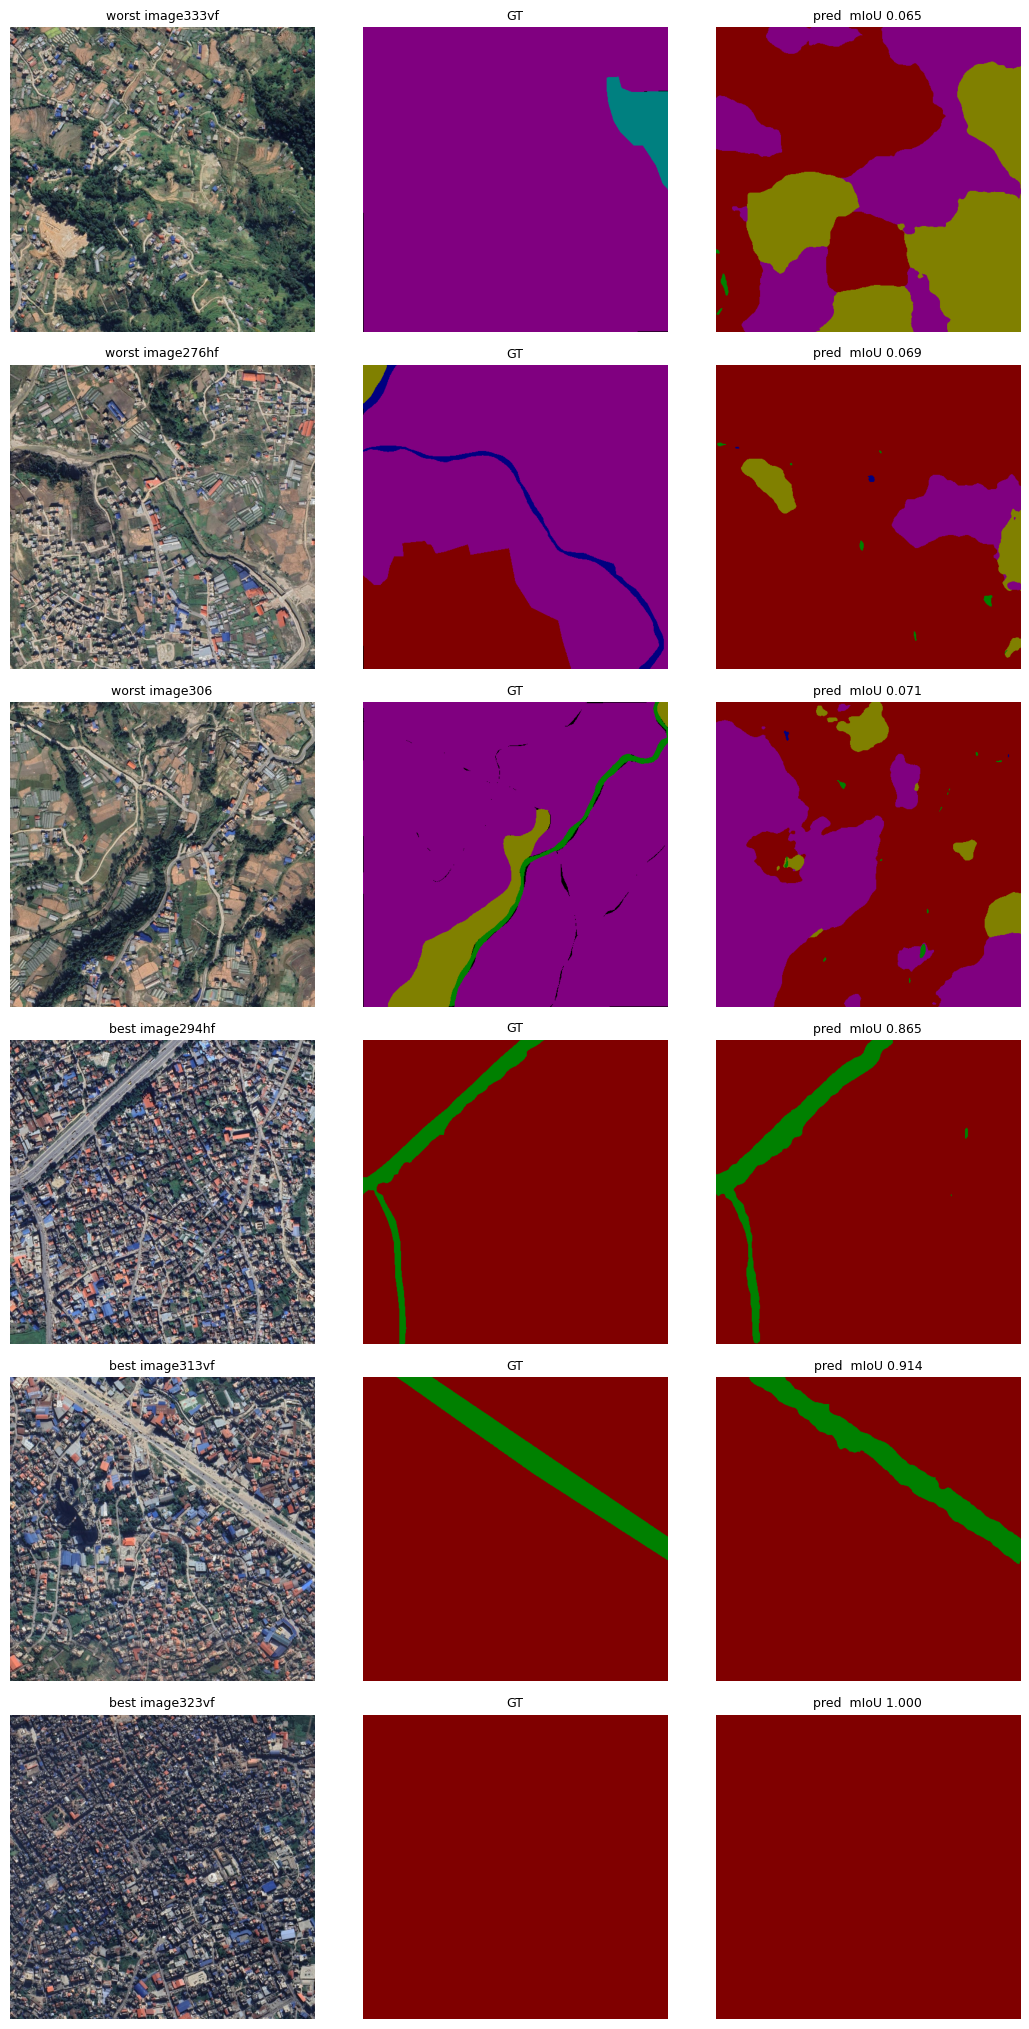

In [28]:
import matplotlib.pyplot as plt
PAL_RGB = np.array([[128,0,0],[0,128,0],[0,0,128],[0,128,128],[128,128,0],[128,0,128]], np.uint8)

def colorize(idx):
    out = np.zeros(idx.shape + (3,), np.uint8)
    for c in range(6): out[idx == c] = PAL_RGB[c]
    return out                                   # ignore stays black

pi = sorted(per_image, key=lambda d: d["mIoU"])
picks = [("worst", r) for r in pi[:3]] + [("best", r) for r in pi[-3:]]
fig, axes = plt.subplots(len(picks), 3, figsize=(11, 3.4 * len(picks)))
for ax_row, (tag, rec) in zip(axes, picks):
    j = rec["row"]
    img = np.asarray(IMAGES[j])[:, :, ::-1]
    gt = np.asarray(MASKS[j])
    x = ((img.astype(np.float32) / 255.0) - IMNET_MEAN) / IMNET_STD
    with torch.no_grad(), torch.cuda.amp.autocast():
        pr = model(torch.from_numpy(x.transpose(2, 0, 1))[None].to(DEVICE)).float().argmax(1)[0].cpu().numpy()
    for ax, im_, t in zip(ax_row, [img, colorize(gt), colorize(pr)],
                          [f'{tag} {STEMS[j]}', f'GT', f'pred  mIoU {rec["mIoU"]:.3f}']):
        ax.imshow(im_); ax.set_title(t, fontsize=9); ax.axis("off")
plt.tight_layout()
p = Path(cfg.OUT_DIR) / f"qualitative_{RUN_TAG}.png"; plt.savefig(p, dpi=130, bbox_inches="tight")
hf_upload(p, p.name); plt.show()

## 25. Normalized confusion matrix

Row-normalized (so the diagonal is producer's accuracy). The two cells to look at first are
**UnusedLand <-> Agricultural** and **River -> UnusedLand**; those are the known spectral confusions
and their magnitude is what the paper should discuss.

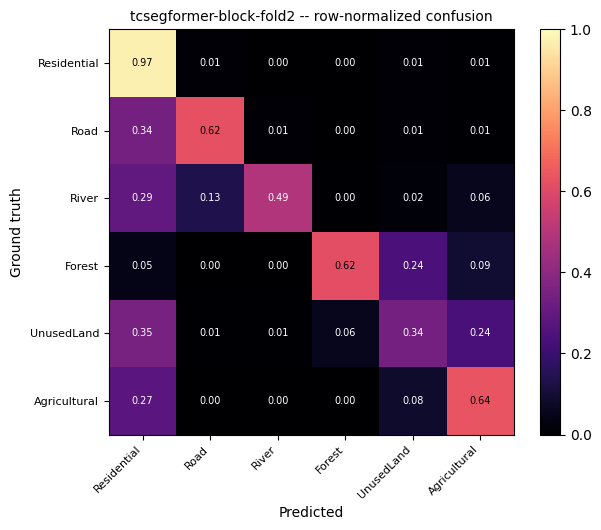

IoU/Agricultural,▁▁▂▂▇▇▇█████████████████████████████████
IoU/Forest,▁▁▁▄▄▄▄▅▅▆▇▇▇▇▇▇▇▇▇▇████████████████████
IoU/Residential,▁▁▂▇████████████████████████████████████
IoU/River,▁▂▄▄▅▆▆▇▇▇▇▇▇▇██████████████████████████
IoU/Road,▁▁▁▁▁▂▃▅▆▆▇▇▇▇▇█████████████████████████
IoU/UnusedLand,▁▂▂▃▃▃▄▄▄▄▇▇▇▇▇█████████████████████████
PA/Agricultural,▁▁▁▂▅▆▇▇████████████████████████████████
PA/Forest,▁▂▂▃▃▄▄▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇███████████████
PA/Residential,▁▄▆█████████████████████████████████████
PA/River,▆██▇▅▁▁▁▁▁▂▂▂▃▃▃▃▃▃▃▃▃▃▃▃▃▃▃▃▃▃▃▃▃▃▃▃▃▃▃
+25,...


In [29]:
cmn = np.array(M_FULL["cm_norm"])
fig, ax = plt.subplots(figsize=(6.4, 5.4))
im = ax.imshow(cmn, cmap="magma", vmin=0, vmax=1)
ax.set_xticks(range(6)); ax.set_yticks(range(6))
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(CLASS_NAMES, fontsize=8)
ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth")
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{cmn[i,j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if cmn[i, j] < 0.55 else "black")
ax.set_title(f"{RUN_TAG} -- row-normalized confusion", fontsize=10)
fig.colorbar(im, fraction=0.046)
plt.tight_layout()
p = Path(cfg.OUT_DIR) / f"confusion_{RUN_TAG}.png"; plt.savefig(p, dpi=140, bbox_inches="tight")
hf_upload(p, p.name); plt.show()
if WB: WB.finish()

## 26. Run checklist

**Before pressing run**

- [ ] Internet ON; `HF_TOKEN` (write) and `WANDB_API_KEY` in Kaggle Secrets.
- [ ] `SPLIT_MODE` and `FOLD` set for this session. Nothing else touched.
- [ ] Section 5 printed "OK: BGR order confirmed" — Residential >> River.
- [ ] Section 9 did **not** print the saturation warning; the effective-number spread is a real number.
- [ ] Section 8 printed a non-zero buffer drop for `block` mode.

**Cost estimates (single T4, batch 16, B0 backbone)**

| Item | Estimate |
|---|---|
| One-time repack (incl. CSA transforms) | 25-40 min, once; save `cache512` as a Kaggle dataset and set `PREBUILT_CACHE` to never repeat it |
| Steps/epoch | ~51 optimizer steps |
| Per epoch | ~10-18 s |
| Per fold (200 epochs, early stop likely 120-160) | ~40-60 min |
| Six runs (3 block + 3 random) | ~4-6 h |
| **Three seeds x 3 folds x 2 split modes** | **~13 h — affordable, and this is the main reason for B0** |
| Peak VRAM | ~4-6 GB at batch 16 including the fp32 Lovasz spike |
| Cache on disk | ~1.6 GB, well inside the /kaggle/working budget |

*(B2 for reference: ~7x the above — ~30-45 s/epoch, ~1.5-2.5 h/fold, single seed only, and the
overfitting signature this dataset already produced on B4 and U-Net-R50.)*

**Report mean +/- std over seeds, not a single number.** With 408 independent base tiles, a
single-seed delta below ~1 mIoU point is not distinguishable from noise. The whole reason B0 makes
the seed grid affordable is so this claim can actually be made.

**Ablation grid** — on B0, and now affordable across all 3 folds rather than fold 2 only:

| Row | Toggles |
|---|---|
| baseline (= plain SegFormer-B0) | `USE_DETAIL=F, CSA=F, CLDICE=F, SAMPLER=F` |
| + sampler | `SAMPLER=T` |
| + clDice | `SAMPLER=T, CLDICE=T` |
| + detail | `SAMPLER=T, CLDICE=T, DETAIL=T` |
| + CSA (full) | all True |
| CSA on other baselines | `CSA=T` applied to U-Net / DeepLabv3+ / HRNet-OCR / UNetFormer — this is the model-agnostic claim and it is the strongest one in the paper |
| capacity check (supplementary) | `BACKBONE=nvidia/segformer-b2-finetuned-ade-512-512, BATCH_SIZE=8, GRAD_ACCUM=2` — one fold, to show the result does not depend on the small backbone |

**Sanity gates for the first 20 epochs.** If any of these fails, stop and diagnose rather than
letting a fold run to 200:

| Epoch | Expect |
|---|---|
| 1 | `train_ce` strictly below its epoch-0 value |
| 5 | mIoU > 0.15 |
| 15 | mIoU > 0.30, Road IoU > 0.05 |
| 30 | mIoU within ~0.05 of the SegFormer-B0 baseline (0.4351) |

Because the refinement is initialised near zero, epoch 0 is effectively plain SegFormer-B0, so this
run should track the B0 baseline curve from the start and then diverge upward. If it tracks *below*
the baseline early, the new modules are fighting the pretrained head — lower `LR_NEW`.

**Two diagnostics worth running before you trust the detail path.** (1) Recompute Road and River IoU
at 1/3/5 px dilation tolerance on the B0 checkpoint: if Road IoU jumps to ~0.50 at 3 px, the failure
is localisation and the detail path is justified; if it stays near 0.35, the failure is *detection*
and an 11-px-receptive-field branch cannot help. (2) Compare against your U-Net's Road IoU — U-Net
already has H/2 and H/1 skips, so if it is not beating SegFormer on Road, the H/4 bottleneck is not
the binding constraint.